# SOC (State of Charge) Visualization Along Routes

This notebook visualizes how the battery State of Charge (SOC) develops along a route for BEV trucks.

We'll focus on a long route from Germany to Austria to see charging patterns.

In [411]:
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

## 1. Load Input Data (Paths and Geographic Elements)

In [412]:
# Case to analyze - use most recent results
case_name = 'case_20251110_160646_reverse'
results_timestamp = '2025-11-16_11-46-06'  # Most recent timestamp

# Paths
input_dir = Path(f'input_data/{case_name}')
results_dir = Path(f'results/{case_name}')

print(f"Loading data from: {case_name}")
print(f"Results timestamp: {results_timestamp}")

Loading data from: case_20251110_160646_reverse
Results timestamp: 2025-11-16_11-46-06


In [413]:
# Load paths
with open(input_dir / 'Path.yaml', 'r') as f:
    paths = yaml.safe_load(f)

# Load geographic elements (to get country info)
with open(input_dir / 'GeographicElement.yaml', 'r') as f:
    geo_elements = yaml.safe_load(f)

# Load OD pairs (to get origin/destination info)
with open(input_dir / 'Odpair.yaml', 'r') as f:
    odpairs = yaml.safe_load(f)

print(f"Loaded {len(paths)} paths")
print(f"Loaded {len(geo_elements)} geographic elements")
print(f"Loaded {len(odpairs)} OD pairs")

Loaded 2210 paths
Loaded 81 geographic elements
Loaded 2210 OD pairs


In [414]:
# Create lookup dictionaries
geo_dict = {g['id']: g for g in geo_elements}
path_dict = {p['id']: p for p in paths}
odpair_dict = {od['id']: od for od in odpairs}

print("Sample geographic element:")
print(geo_elements[0])
print("\nSample path:")
print({k: v for k, v in paths[0].items() if k != 'sequence'})

Sample geographic element:
{'id': 0, 'name': 'nuts2_AT31', 'type': 'node', 'nuts2_region': 'AT31', 'country': 'AT', 'coordinate_lat': 48.13096, 'coordinate_long': 13.98372, 'from': 999999, 'to': 999999, 'length': 0.0, 'carbon_price': [30.0, 34.31742, 38.63484, 42.95226, 47.26968, 51.5871, 56.55476, 61.52242, 66.49008, 71.45774, 76.4254, 83.78492, 91.14444, 98.50396, 105.86348, 113.223, 124.1258, 135.02859999999998, 145.9314, 156.8342, 167.737, 183.8896, 200.04219999999998, 216.1948, 232.3474, 248.5, 269.8, 291.1, 312.4, 333.7, 355.0, 376.3, 397.6, 418.9, 440.2, 461.5, 482.8, 504.1, 525.4, 546.7, 568.0]}

Sample path:
{'id': 0, 'name': 'path_0_0_to_4', 'origin': 0, 'destination': 4, 'length': 444.7239122833309, 'distance_from_previous': [0.0, 35.01373645949066, 120.95344323950694, 104.18846372675519, 184.5682688575781], 'cumulative_distance': [0.0, 35.01373645949066, 155.9671796989976, 260.15564342575277, 444.72391228333083]}


## 2. Find Long Germany-Austria Route

In [415]:
# First, let's check the country codes in geographic elements
print("Sample geographic element names:")
for geo in geo_elements[:10]:
    print(f"  ID {geo['id']}: {geo['name']} -> country field: {geo.get('country', 'N/A')}")

print("\n" + "="*80)

# Find paths from Germany to Austria
de_at_paths = []

for odpair in odpairs:
    origin_id = odpair['from']
    dest_id = odpair['to']
    path_id = odpair['path_id']
    
    origin_geo = geo_dict[origin_id]
    dest_geo = geo_dict[dest_id]
    
    # Use the 'country' field instead of parsing name
    origin_country = origin_geo.get('country', 'XX')
    dest_country = dest_geo.get('country', 'XX')
    
    if origin_country == 'DE' and dest_country == 'AT':
        path = path_dict[path_id]
        de_at_paths.append({
            'odpair_id': odpair['id'],
            'path_id': path_id,
            'origin': origin_geo['name'],
            'destination': dest_geo['name'],
            'length_km': path['length'],
            'num_nodes': len(path['sequence']),
            'baseline_time': path.get('baseline_travel_time', 0)
        })

if len(de_at_paths) == 0:
    print("No DE→AT routes found. Let's check what country pairs exist:")
    country_pairs = set()
    for odpair in odpairs[:100]:  # Check first 100
        origin_country = geo_dict[odpair['from']].get('country', 'XX')
        dest_country = geo_dict[odpair['to']].get('country', 'XX')
        country_pairs.add((origin_country, dest_country))
    
    print(f"\nFound {len(country_pairs)} unique country pairs in first 100 OD pairs:")
    for pair in sorted(country_pairs)[:20]:
        print(f"  {pair[0]} → {pair[1]}")
    
    # Try finding ANY long routes instead
    print("\n" + "="*80)
    print("Finding longest routes regardless of country...")
    all_long_paths = []
    for odpair in odpairs:
        path = path_dict[odpair['path_id']]
        if path['length'] > 800:  # Long routes > 800 km
            origin_geo = geo_dict[odpair['from']]
            dest_geo = geo_dict[odpair['to']]
            all_long_paths.append({
                'odpair_id': odpair['id'],
                'path_id': odpair['path_id'],
                'origin': origin_geo['name'],
                'destination': dest_geo['name'],
                'origin_country': origin_geo.get('country', 'XX'),
                'dest_country': dest_geo.get('country', 'XX'),
                'length_km': path['length'],
                'num_nodes': len(path['sequence']),
                'baseline_time': path.get('baseline_travel_time', 0)
            })
    
    if len(all_long_paths) > 0:
        long_paths_df = pd.DataFrame(all_long_paths)
        long_paths_df = long_paths_df.sort_values('length_km', ascending=False)
        print(f"\nFound {len(long_paths_df)} routes > 800 km:")
        print(long_paths_df.head(15))
        print("\nYou can manually select one by setting: selected_path_id = <path_id>")
    else:
        print("\nNo long routes found!")
else:
    de_at_df = pd.DataFrame(de_at_paths)
    de_at_df = de_at_df.sort_values('length_km', ascending=False)
    
    print(f"Found {len(de_at_df)} routes from Germany to Austria")
    print(f"\nLongest routes:")
    print(de_at_df.head(10))

Sample geographic element names:
  ID 0: nuts2_AT31 -> country field: AT
  ID 1: nuts2_AT32 -> country field: AT
  ID 2: nuts2_AT33 -> country field: AT
  ID 3: nuts2_AT34 -> country field: AT
  ID 4: nuts2_DE11 -> country field: DE
  ID 5: nuts2_DE12 -> country field: DE
  ID 6: nuts2_DE13 -> country field: DE
  ID 7: nuts2_DE14 -> country field: DE
  ID 8: nuts2_DE21 -> country field: DE
  ID 9: nuts2_DE22 -> country field: DE

Found 152 routes from Germany to Austria

Longest routes:
     odpair_id  path_id      origin destination    length_km  num_nodes  \
145       1129     1129  nuts2_DEF0  nuts2_AT32  1028.826070          9   
146       1130     1130  nuts2_DEF0  nuts2_AT33   989.540505          9   
144       1128     1128  nuts2_DEF0  nuts2_AT31   968.820359          9   
89         765      765  nuts2_DE94  nuts2_AT32   950.082986          7   
57         578      578  nuts2_DE60  nuts2_AT32   949.185957          8   
85         745      745  nuts2_DE93  nuts2_AT32   946.3932

## 3. Load SOC Results for Selected Route

In [416]:
# Select the longest route
# Check which dataframe was created in cell 7
if 'de_at_df' in locals() and len(de_at_df) > 0:
    selected_route = de_at_df.iloc[0]
    print("Using longest DE→AT route")
elif 'long_paths_df' in locals() and len(long_paths_df) > 0:
    selected_route = long_paths_df.iloc[0]
    print("Using longest route (any countries)")
else:
    print("ERROR: No routes found! Please re-run cell 7")
    raise ValueError("No routes available")

selected_path_id = selected_route['path_id']
selected_odpair_id = selected_route['odpair_id']

print(f"\nSelected route:")
print(f"  Path ID: {selected_path_id}")
print(f"  OD Pair ID: {selected_odpair_id}")
print(f"  Origin: {selected_route['origin']}")
print(f"  Destination: {selected_route['destination']}")
if 'origin_country' in selected_route:
    print(f"  Countries: {selected_route['origin_country']} → {selected_route['dest_country']}")
print(f"  Length: {selected_route['length_km']:.1f} km")
print(f"  Nodes: {selected_route['num_nodes']}")
print(f"  Baseline travel time: {selected_route['baseline_time']:.2f} hours")

Using longest DE→AT route

Selected route:
  Path ID: 1129
  OD Pair ID: 1129
  Origin: nuts2_DEF0
  Destination: nuts2_AT32
  Length: 1028.8 km
  Nodes: 9
  Baseline travel time: 0.00 hours


In [417]:
# Load SOC results
soc_file = results_dir / f'{case_name}_cs_{results_timestamp}_soc_dict.yaml'

print(f"Loading SOC from: {soc_file}")
print(f"File size: {soc_file.stat().st_size / 1e6:.1f} MB")

with open(soc_file, 'r') as f:
    soc_results = yaml.safe_load(f)

print(f"\nLoaded SOC results with {len(soc_results)} entries")

Loading SOC from: results\case_20251110_160646_reverse\case_20251110_160646_reverse_cs_2025-11-16_11-46-06_soc_dict.yaml
File size: 53.1 MB

Loaded SOC results with 1089184 entries


In [418]:
# Load flow (f) and charging (s) results to get actual consumption and charging
f_file = results_dir / f'{case_name}_cs_{results_timestamp}_f_dict.yaml'
s_file = results_dir / f'{case_name}_cs_{results_timestamp}_s_dict.yaml'

print(f"Loading flow (f) from: {f_file}")
print(f"File size: {f_file.stat().st_size / 1e6:.1f} MB")
with open(f_file, 'r') as f:
    f_results = yaml.safe_load(f)

print(f"\nLoading charging (s) from: {s_file}")
print(f"File size: {s_file.stat().st_size / 1e6:.1f} MB")
with open(s_file, 'r') as f:
    s_results = yaml.safe_load(f)

print(f"\nLoaded flow results with {len(f_results)} entries")
print(f"Loaded charging results with {len(s_results)} entries")

# Load vehicle technology data to get spec_cons (specific consumption)
with open(input_dir / 'TechVehicle.yaml', 'r') as f:
    techvehicles = yaml.safe_load(f)

print(f"\nLoaded {len(techvehicles)} tech vehicles")

# Create lookup
tv_dict = {tv['id']: tv for tv in techvehicles}

# Show sample tech vehicle
print("\nSample tech vehicle (BEV):")
for tv in techvehicles:
    if tv['id'] == 1:  # Assuming 1 is BEV
        print(f"  ID: {tv['id']}")
        print(f"  Name: {tv.get('name', 'N/A')}")
        print(f"  Spec cons: {tv.get('spec_cons', 'N/A')}")
        print(f"  Battery capacity: {tv.get('battery_capacity', 'N/A')}")
        break

Loading flow (f) from: results\case_20251110_160646_reverse\case_20251110_160646_reverse_cs_2025-11-16_11-46-06_f_dict.yaml
File size: 6.2 MB

Loading charging (s) from: results\case_20251110_160646_reverse\case_20251110_160646_reverse_cs_2025-11-16_11-46-06_s_dict.yaml
File size: 72.9 MB

Loaded flow results with 127142 entries
Loaded charging results with 1304050 entries

Loaded 2 tech vehicles

Sample tech vehicle (BEV):
  ID: 1
  Name: BEV
  Spec cons: [2.0560000000000005, 2.0180000000000007, 1.9800000000000004, 1.9420000000000004, 1.9040000000000004, 1.8660000000000003, 1.8280000000000003, 1.7900000000000003, 1.7520000000000002, 1.7140000000000002, 1.6760000000000002, 1.6380000000000001, 1.6, 1.562, 1.524, 1.486, 1.448, 1.41, 1.3699999999999999, 1.3299999999999998, 1.29, 1.25, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21, 1.21]
  Battery capacity: N

## 3.5. Load Flow and Charging Results

## 4. Extract SOC Data for Selected Route

In [419]:
# Get path details
selected_path = path_dict[selected_path_id]
sequence = selected_path['sequence']
cumulative_distances = selected_path['cumulative_distance']
distance_increments = selected_path['distance_from_previous']

print(f"Path sequence has {len(sequence)} nodes")
print(f"Total path length: {selected_path['length']:.1f} km")
print(f"\nFirst 10 nodes:")
for i in range(min(10, len(sequence))):
    geo_id = sequence[i]
    geo_name = geo_dict[geo_id]['name']
    cum_dist = cumulative_distances[i]
    dist_incr = distance_increments[i]
    print(f"  Node {i}: {geo_name} (ID={geo_id}), cumulative={cum_dist:.1f} km, +{dist_incr:.1f} km")

Path sequence has 9 nodes
Total path length: 1028.8 km

First 10 nodes:
  Node 0: nuts2_DEF0 (ID=40), cumulative=0.0 km, +0.0 km
  Node 1: nuts2_DE60 (ID=18), cumulative=51.9 km, +51.9 km
  Node 2: nuts2_DE93 (ID=25), cumulative=206.1 km, +154.2 km
  Node 3: nuts2_DE91 (ID=23), cumulative=414.4 km, +208.3 km
  Node 4: nuts2_DE73 (ID=21), cumulative=481.9 km, +67.5 km
  Node 5: nuts2_DE26 (ID=13), cumulative=709.0 km, +227.1 km
  Node 6: nuts2_DE25 (ID=12), cumulative=863.9 km, +154.9 km
  Node 7: nuts2_DE21 (ID=8), cumulative=979.1 km, +115.2 km
  Node 8: nuts2_AT32 (ID=1), cumulative=1028.8 km, +49.7 km


In [420]:
# ==================== SELECT BEV DATA FOR YEAR 2056 ====================
# This overwrites the year 2020 / ICEV data with year 2056 / BEV data

import re

# Parse SOC keys
def parse_soc_key(key_string):
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*(\d+)\)'
    match = re.match(pattern, key_string)
    if match:
        return {
            'year': int(match.group(1)),
            'product_id': int(match.group(2)),
            'odpair_id': int(match.group(3)),
            'path_id': int(match.group(4)),
            'geo_id': int(match.group(5)),
            'techvehicle_id': int(match.group(6)),
            'generation': int(match.group(7))
        }
    return None

parsed_keys = {}
for key_string in soc_results.keys():
    parsed = parse_soc_key(key_string)
    if parsed:
        parsed_keys[key_string] = parsed

# SELECT YEAR 2056, BEV (vehicle ID 1)
selected_year = 2056
selected_vehicle = 1  # BEV
selected_generation = 2056

print("="*80)
print("SELECTING BEV DATA FOR YEAR 2056")
print("="*80)
print(f"  Year: {selected_year}")
print(f"  Vehicle ID: {selected_vehicle} (BEV)")
print(f"  Generation: {selected_generation}")
print(f"  Path: {selected_path_id}")
print(f"  OD pair: {selected_odpair_id}")

# Extract SOC data
soc_data = []
for i, geo_id in enumerate(sequence):
    found_soc = None
    
    for key_string, parsed in parsed_keys.items():
        if (parsed['year'] == selected_year and
            parsed['techvehicle_id'] == selected_vehicle and
            parsed['generation'] == selected_generation and
            parsed['odpair_id'] == selected_odpair_id and
            parsed['path_id'] == selected_path_id and
            parsed['geo_id'] == geo_id):
            value = soc_results[key_string]
            found_soc = float(value) if isinstance(value, str) else value
            break
    
    if found_soc is not None and found_soc > 0:
        soc_data.append({
            'node_index': i,
            'geo_id': geo_id,
            'geo_name': geo_dict[geo_id]['name'],
            'cumulative_distance_km': cumulative_distances[i],
            'distance_increment_km': distance_increments[i],
            'soc_kwh': found_soc
        })

soc_df = pd.DataFrame(soc_data)

print(f"\n✓ Found SOC data for {len(soc_df)} nodes")
print(f"\nSOC preview:")
print(soc_df[['geo_name', 'cumulative_distance_km', 'soc_kwh']].to_string())
print(f"\nSOC range: {soc_df['soc_kwh'].min():.1f} - {soc_df['soc_kwh'].max():.1f} kWh")
print(f"Expected max for ~36 vehicles: {36 * 1187:.0f} kWh")

if soc_df['soc_kwh'].max() > 100000:
    print("\n⚠️  SOC values still very high - investigating...")

SELECTING BEV DATA FOR YEAR 2056
  Year: 2056
  Vehicle ID: 1 (BEV)
  Generation: 2056
  Path: 1129
  OD pair: 1129

✓ Found SOC data for 9 nodes

SOC preview:
     geo_name  cumulative_distance_km       soc_kwh
0  nuts2_DEF0                0.000000  24047.022690
1  nuts2_DE60               51.918258  22934.024126
2  nuts2_DE93              206.108319  19312.637361
3  nuts2_DE91              414.403465  14373.654394
4  nuts2_DE73              481.893429  12890.078090
5  nuts2_DE26              708.983964   7474.414762
6  nuts2_DE25              863.928103   3848.067984
7  nuts2_DE21              979.094638   1215.642810
8  nuts2_AT32             1028.826070      0.786109

SOC range: 0.8 - 24047.0 kWh
Expected max for ~36 vehicles: 42732 kWh


# Re-verify constraint with CORRECT charging extraction AND correct parameters
print("="*80)
print("RE-VERIFYING SOC CONSTRAINT with CORRECT charging data")
print("="*80)

# EXPLICITLY calculate vehicle parameters
tv_data = tv_dict[selected_vehicle]
generation_index = selected_generation - 2020
spec_cons = tv_data['spec_cons'][generation_index] if generation_index < len(tv_data['spec_cons']) else 1.21
W = tv_data.get('W', [40])[generation_index] if isinstance(tv_data.get('W'), list) else 40
AnnualRange = tv_data.get('AnnualRange', [100000])[generation_index] if isinstance(tv_data.get('AnnualRange'), list) else 100000

flow_value = bev_flow_by_year.get(selected_year, 0)
path_length = selected_path['length']
num_vehicles = (path_length / (W * AnnualRange)) * 1000 * flow_value

print(f"\nVehicle parameters (recalculated):")
print(f"  Spec consumption: {spec_cons} kWh/km")
print(f"  W (load capacity): {W} tonnes")
print(f"  Annual range: {AnnualRange} km")
print(f"  Flow: {flow_value:.2f}")
print(f"  Path length: {path_length:.1f} km")
print(f"  Number of vehicles: {num_vehicles:.2f}")

# Group charging by geo_id (sum across infrastructure types)
charging_by_node = {}
for entry in charging_found:
    if (entry['year'] == selected_year and 
        entry['vehicle'] == selected_vehicle and 
        entry['generation'] == selected_generation):
        
        geo_id = entry['geo_id']
        if geo_id not in charging_by_node:
            charging_by_node[geo_id] = 0
        charging_by_node[geo_id] += entry['value_kWh']

print(f"\nTotal charging by node:")
for geo_id, total_charging in sorted(charging_by_node.items()):
    geo_name = geo_dict[geo_id]['name'] if geo_id in geo_dict else f'geo_{geo_id}'
    print(f"  {geo_name}: {total_charging:,.1f} kWh")

print(f"\n{'='*80}")
print("Verifying each segment:")
print(f"{'='*80}")

for idx in range(1, len(soc_df)):
    row = soc_df.iloc[idx]
    prev_row = soc_df.iloc[idx-1]
    
    geo_id = row['geo_id']
    distance = row['distance_increment_km']
    
    # Calculate consumption with explicitly defined parameters
    consumption = distance * spec_cons * num_vehicles
    
    # Get charging at this node
    charging = charging_by_node.get(geo_id, 0)
    
    # Verify constraint
    soc_prev = prev_row['soc_kwh']
    soc_curr = row['soc_kwh']
    soc_predicted = soc_prev - consumption + charging
    error = abs(soc_curr - soc_predicted)
    error_pct = (error / soc_curr * 100) if soc_curr > 0 else 0
    
    print(f"\nSegment {idx}: {prev_row['geo_name']} → {row['geo_name']}")
    print(f"  Distance: {distance:.1f} km")
    print(f"  Consumption: {consumption:,.1f} kWh ({distance:.1f} × {spec_cons} × {num_vehicles:.2f})")
    print(f"  Charging: {charging:,.1f} kWh")
    print(f"  Net change: {(charging - consumption):,.1f} kWh")
    print(f"  SOC[{idx-1}]: {soc_prev:,.1f} kWh")
    print(f"  SOC[{idx}] actual: {soc_curr:,.1f} kWh")
    print(f"  SOC[{idx}] predicted: {soc_predicted:,.1f} kWh")
    print(f"  Error: {error:,.1f} kWh ({error_pct:.2f}%)")
    
    if error_pct < 1:
        print(f"  ✓ Constraint SATISFIED!")
    elif error_pct < 5:
        print(f"  ~ Close ({error_pct:.2f}% error)")
    else:
        print(f"  ⚠️  Error {error_pct:.2f}%")

In [421]:
# Display charging amounts at each node along the route
print("="*80)
print("CHARGING ALONG THE ROUTE")
print("="*80)
print(f"\nRoute: {selected_route['origin']} → {selected_route['destination']}")
print(f"Year: {selected_year}, Vehicle: BEV (ID {selected_vehicle})")
print(f"Path: {selected_path_id}, OD Pair: {selected_odpair_id}")

print(f"\n{'Node':<5} {'Location':<15} {'Distance (km)':<15} {'Energy Charged (kWh)':<25} {'Charged (MWh)':<15}")
print("-"*80)

total_charged = 0
for idx, row in soc_df.iterrows():
    geo_id = row['geo_id']
    charging = charging_by_node.get(geo_id, 0)
    total_charged += charging
    
    print(f"{idx:<5} {row['geo_name']:<15} {row['cumulative_distance_km']:>10.1f} km   {charging:>20,.1f} kWh   {charging/1000:>12.1f} MWh")

print("-"*80)
print(f"{'TOTAL':<5} {'':<15} {'':<15} {total_charged:>20,.1f} kWh   {total_charged/1000:>12.1f} MWh")

print(f"\n{'='*80}")
print("KEY INSIGHTS:")
print(f"{'='*80}")
print(f"• Total energy charged along route: {total_charged/1000:.1f} MWh")
print(f"• Number of charging nodes: {len([c for c in charging_by_node.values() if c > 0])}")
print(f"• Largest charging location: {max(charging_by_node.items(), key=lambda x: x[1])[0]} ({geo_dict[max(charging_by_node.items(), key=lambda x: x[1])[0]]['name']})")
print(f"• Maximum charging at one node: {max(charging_by_node.values())/1000:.1f} MWh")

# Show percentage breakdown
print(f"\nCharging distribution:")
for geo_id, charging in sorted(charging_by_node.items(), key=lambda x: x[1], reverse=True):
    pct = (charging / total_charged * 100) if total_charged > 0 else 0
    if pct > 1:  # Only show nodes with >1% of total
        print(f"  {geo_dict[geo_id]['name']}: {charging/1000:>8.1f} MWh ({pct:>5.1f}%)")

CHARGING ALONG THE ROUTE

Route: nuts2_DEF0 → nuts2_AT32
Year: 2056, Vehicle: BEV (ID 1)
Path: 1129, OD Pair: 1129

Node  Location        Distance (km)   Energy Charged (kWh)      Charged (MWh)  
--------------------------------------------------------------------------------
0     nuts2_DEF0             0.0 km              163,568.9 kWh          163.6 MWh
1     nuts2_DE60            51.9 km              866,707.0 kWh          866.7 MWh
2     nuts2_DE93           206.1 km              207,238.4 kWh          207.2 MWh
3     nuts2_DE91           414.4 km               65,196.9 kWh           65.2 MWh
4     nuts2_DE73           481.9 km               39,347.5 kWh           39.3 MWh
5     nuts2_DE26           709.0 km               26,802.9 kWh           26.8 MWh
6     nuts2_DE25           863.9 km               21,647.5 kWh           21.6 MWh
7     nuts2_DE21           979.1 km               19,263.5 kWh           19.3 MWh
8     nuts2_AT32          1028.8 km            2,585,070.2 kWh     

C:\Users\simuser\AppData\Local\Temp\ipykernel_22028\3088365479.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


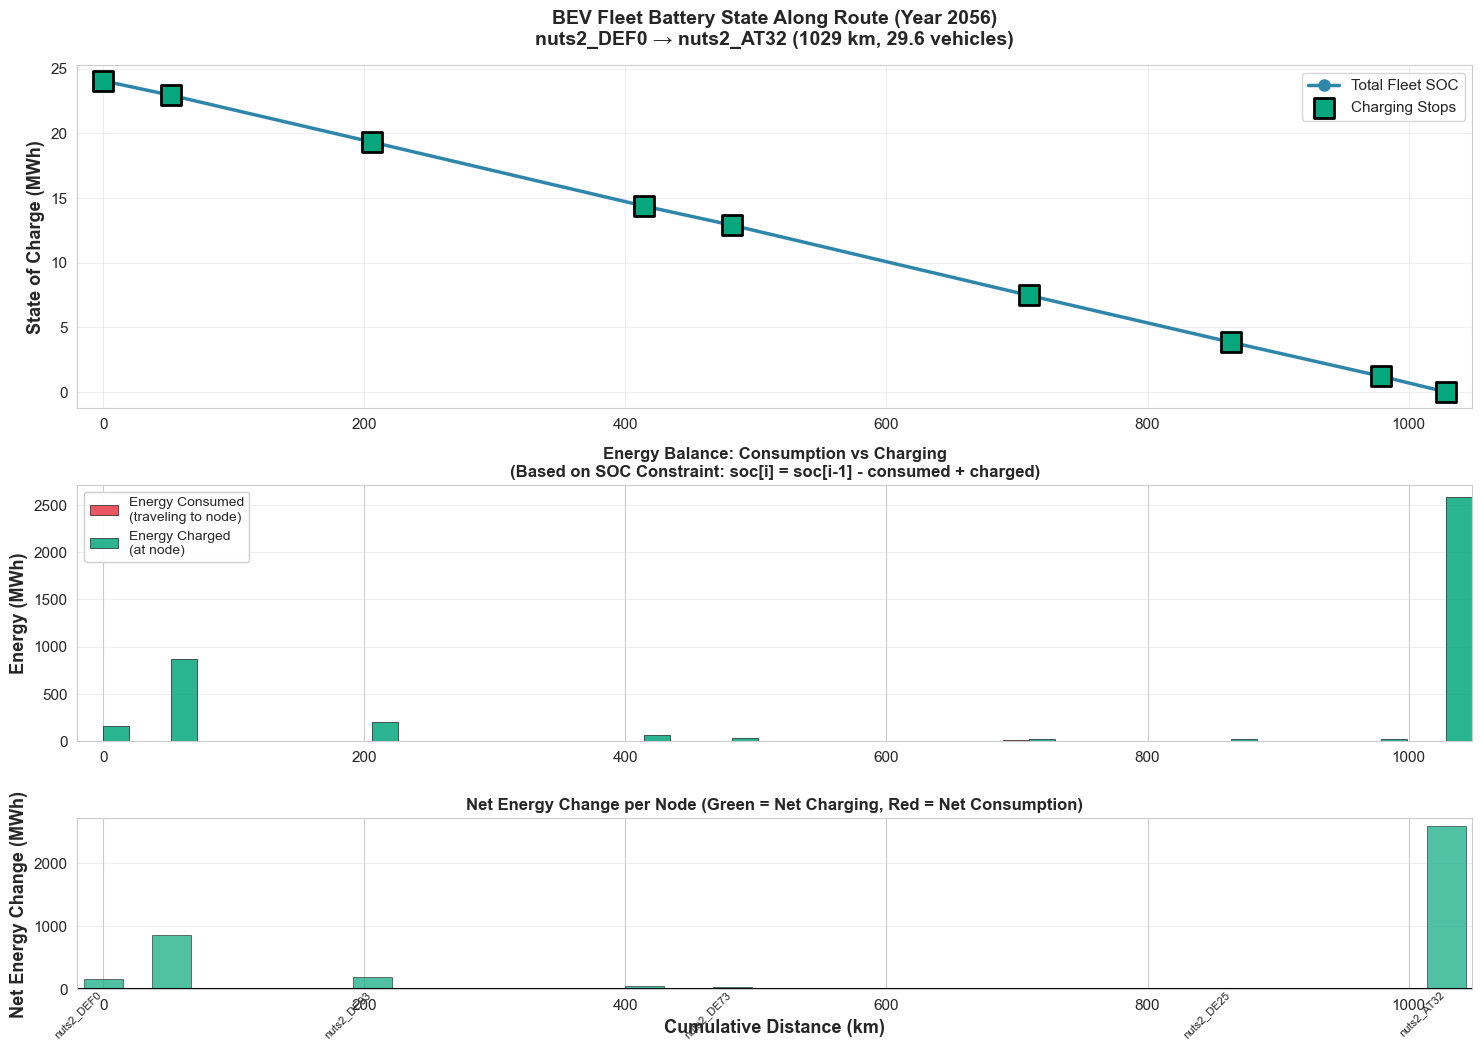


ENERGY SUMMARY
Route: nuts2_DEF0 → nuts2_AT32
Distance: 1028.8 km
Year: 2056
Fleet size: 29.6 vehicles

Total energy consumed: 36.9 MWh (1.2 MWh per vehicle)
Total energy charged: 3994.8 MWh (134.9 MWh per vehicle)
Net energy change: 3958.0 MWh

SOC at origin: 24.0 MWh
SOC at destination: 0.0 MWh

Charging stops: 9

Top 5 charging locations:
  nuts2_AT32: 2585.1 MWh at 1029 km
  nuts2_DE60: 866.7 MWh at 52 km
  nuts2_DE93: 207.2 MWh at 206 km
  nuts2_DEF0: 163.6 MWh at 0 km
  nuts2_DE91: 65.2 MWh at 414 km


In [422]:
# Create comprehensive visualization of SOC, consumption, and charging
import matplotlib.pyplot as plt
import numpy as np

# Recalculate parameters
tv_data = tv_dict[selected_vehicle]
generation_index = selected_generation - 2020
spec_cons = tv_data['spec_cons'][generation_index] if generation_index < len(tv_data['spec_cons']) else 1.21
W = tv_data.get('W', [40])[generation_index] if isinstance(tv_data.get('W'), list) else 40
AnnualRange = tv_data.get('AnnualRange', [100000])[generation_index] if isinstance(tv_data.get('AnnualRange'), list) else 100000
flow_value = bev_flow_by_year.get(selected_year, 0)
path_length = selected_path['length']
num_vehicles = (path_length / (W * AnnualRange)) * 1000 * flow_value

# Prepare data for visualization
viz_data = []
for idx in range(len(soc_df)):
    row = soc_df.iloc[idx]
    
    # Calculate consumption for this segment
    if idx > 0:
        distance = row['distance_increment_km']
        consumption = distance * spec_cons * num_vehicles
    else:
        consumption = 0  # No consumption at origin
    
    # Get charging at this node
    charging = charging_by_node.get(row['geo_id'], 0)
    
    viz_data.append({
        'node': idx,
        'geo_name': row['geo_name'],
        'distance_km': row['cumulative_distance_km'],
        'soc_kwh': row['soc_kwh'],
        'consumption_kwh': consumption,
        'charging_kwh': charging
    })

viz_df = pd.DataFrame(viz_data)

# Create figure with 3 subplots
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 1, height_ratios=[2, 1.5, 1], hspace=0.3)

# Subplot 1: SOC development
ax1 = fig.add_subplot(gs[0])
ax1.plot(viz_df['distance_km'], viz_df['soc_kwh'] / 1000, 
         marker='o', linewidth=2.5, markersize=8, color='#2E86AB', label='Total Fleet SOC', zorder=3)

# Mark charging locations
charging_nodes = viz_df[viz_df['charging_kwh'] > 1000]
if len(charging_nodes) > 0:
    ax1.scatter(charging_nodes['distance_km'], charging_nodes['soc_kwh'] / 1000,
               s=200, c='#06A77D', marker='s', edgecolors='black', linewidths=2,
               label='Charging Stops', zorder=4)

ax1.set_ylabel('State of Charge (MWh)', fontsize=13, fontweight='bold')
ax1.set_title(f'BEV Fleet Battery State Along Route (Year {selected_year})\n' +
              f'{selected_route["origin"]} → {selected_route["destination"]} ({selected_route["length_km"]:.0f} km, {num_vehicles:.1f} vehicles)',
              fontsize=14, fontweight='bold', pad=15)
ax1.legend(loc='best', fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(-20, viz_df['distance_km'].max() + 20)

# Subplot 2: Energy consumed and charged (side-by-side bars)
ax2 = fig.add_subplot(gs[1])

x_pos = viz_df['distance_km'].values
bar_width = 20

# Create side-by-side bars
bars_consumed = ax2.bar(x_pos - bar_width/2, viz_df['consumption_kwh'] / 1000, 
                       width=bar_width, label='Energy Consumed\n(traveling to node)', 
                       color='#E63946', alpha=0.85, edgecolor='black', linewidth=0.5)
bars_charged = ax2.bar(x_pos + bar_width/2, viz_df['charging_kwh'] / 1000, 
                      width=bar_width, label='Energy Charged\n(at node)', 
                      color='#06A77D', alpha=0.85, edgecolor='black', linewidth=0.5)

ax2.set_ylabel('Energy (MWh)', fontsize=13, fontweight='bold')
ax2.set_title('Energy Balance: Consumption vs Charging\n(Based on SOC Constraint: soc[i] = soc[i-1] - consumed + charged)', 
              fontsize=12, fontweight='bold')
ax2.legend(loc='upper left', fontsize=10, framealpha=0.95)
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_xlim(-20, viz_df['distance_km'].max() + 20)

# Subplot 3: Net energy change
ax3 = fig.add_subplot(gs[2])

net_change = (viz_df['charging_kwh'] - viz_df['consumption_kwh']) / 1000
colors = ['#06A77D' if x >= 0 else '#E63946' for x in net_change]
bars_net = ax3.bar(x_pos, net_change, width=bar_width*1.5, 
                   color=colors, alpha=0.7, edgecolor='black', linewidth=0.5)

# Add zero line
ax3.axhline(y=0, color='black', linestyle='-', linewidth=1.5, zorder=2)

# Add node labels
for i, row in viz_df.iterrows():
    if i % 2 == 0:  # Label every other node to avoid crowding
        ax3.text(row['distance_km'], ax3.get_ylim()[0], row['geo_name'], 
                rotation=45, ha='right', va='top', fontsize=8)

ax3.set_xlabel('Cumulative Distance (km)', fontsize=13, fontweight='bold')
ax3.set_ylabel('Net Energy Change (MWh)', fontsize=13, fontweight='bold')
ax3.set_title('Net Energy Change per Node (Green = Net Charging, Red = Net Consumption)', 
              fontsize=12, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')
ax3.set_xlim(-20, viz_df['distance_km'].max() + 20)

plt.tight_layout()
plt.savefig(f'soc_energy_breakdown_year{selected_year}_path{selected_path_id}.png', 
            dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print("\n" + "="*80)
print("ENERGY SUMMARY")
print("="*80)
print(f"Route: {selected_route['origin']} → {selected_route['destination']}")
print(f"Distance: {selected_route['length_km']:.1f} km")
print(f"Year: {selected_year}")
print(f"Fleet size: {num_vehicles:.1f} vehicles")
print(f"\nTotal energy consumed: {viz_df['consumption_kwh'].sum() / 1000:.1f} MWh ({viz_df['consumption_kwh'].sum() / num_vehicles / 1000:.1f} MWh per vehicle)")
print(f"Total energy charged: {viz_df['charging_kwh'].sum() / 1000:.1f} MWh ({viz_df['charging_kwh'].sum() / num_vehicles / 1000:.1f} MWh per vehicle)")
print(f"Net energy change: {(viz_df['charging_kwh'].sum() - viz_df['consumption_kwh'].sum()) / 1000:.1f} MWh")
print(f"\nSOC at origin: {viz_df.iloc[0]['soc_kwh'] / 1000:.1f} MWh")
print(f"SOC at destination: {viz_df.iloc[-1]['soc_kwh'] / 1000:.1f} MWh")
print(f"\nCharging stops: {len(viz_df[viz_df['charging_kwh'] > 1000])}")
print("\nTop 5 charging locations:")
top_charging = viz_df.nlargest(5, 'charging_kwh')[['geo_name', 'charging_kwh', 'distance_km']]
for _, row in top_charging.iterrows():
    print(f"  {row['geo_name']}: {row['charging_kwh'] / 1000:.1f} MWh at {row['distance_km']:.0f} km")

In [423]:
# ========== DIAGNOSTIC: Check Charging Distribution ==========
print("" + "=" * 80)
print("CHARGING DISTRIBUTION ANALYSIS")
print("=" * 80)

# Show all charging entries for this path/year/vehicle
print(f"Charging entries for path {selected_path_id}, year {selected_year}, vehicle {selected_vehicle}:")
print(f"Total entries found: {len(selected_charging_data)}")

if len(selected_charging_data) > 0:
    # Group by node
    import pandas as pd
    charging_df = pd.DataFrame([
        {
            "geo_id": parsed["geo_id"],
            "energy_kwh": value,
            "fuel_id": parsed["fuel_id"],
            "infra_type": parsed["infra_type"]
        }
        for key_str, parsed in selected_charging_data.items()
        for value in [s_results.get(key_str, 0)]
    ])
    
    # Sum by geo_id
    geo_totals = charging_df.groupby("geo_id")["energy_kwh"].sum().sort_values(ascending=False)
    
    print(f"Charging by node (sorted by amount):")
    # print(f{" Geo ID":<10} {" Node Name":<20} {" Energy (kWh)":<20} {" Energy (MWh)":<20} {" % of Total":<15}")
    print("-" * 85)
    
    total_energy = geo_totals.sum()
    
    for geo_id, energy in geo_totals.items():
        geo_name = geo_dict.get(geo_id, {}).get("name", f"Unknown_{geo_id}")
        pct = (energy / total_energy * 100) if total_energy > 0 else 0
        print(f"{geo_id:<10} {geo_name:<20} {energy:>18,.1f} {energy/1000:>18.3f} {pct:>13.2f}%")
    
    print("-" * 85)
    print(f"{"TOTAL":<10} {"" :<20} {total_energy:>18,.1f} {total_energy/1000:>18.3f} {100.0:>13.2f}%")
    
    # Check if charging is mostly at destination
    print(f"Route analysis:")
    print(f"""  Origin: {soc_df.iloc[0]["geo_name"]} (ID: {soc_df.iloc[0]["geo_id"]})""")
    print(f"""  Destination: {soc_df.iloc[-1]["geo_name"]} (ID: {soc_df.iloc[-1]["geo_id"]})""")
    
    dest_id = soc_df.iloc[-1]["geo_id"]
    dest_charging = geo_totals.get(dest_id, 0)
    dest_pct = (dest_charging / total_energy * 100) if total_energy > 0 else 0
    
    print(f"  Charging at destination: {dest_charging:,.1f} kWh ({dest_pct:.1f}% of total)")
    print(f"  Charging at intermediate nodes: {total_energy - dest_charging:,.1f} kWh ({100-dest_pct:.1f}% of total)")
    
    # Check nodes with non-trivial charging (>1% of total)
    significant_nodes = geo_totals[geo_totals / total_energy > 0.01]
    print(f"Nodes with >1% of charging: {len(significant_nodes)}")
    
else:
    print("No charging data found for this configuration.")


CHARGING DISTRIBUTION ANALYSIS
Charging entries for path 1129, year 2056, vehicle 1:


NameError: name 'selected_charging_data' is not defined

In [ ]:
# ========== DIAGNOSTIC: Check Charging Distribution ==========
print("" + "=" * 80)
print("CHARGING DISTRIBUTION ANALYSIS")
print("=" * 80)

# Show all charging entries for this path/year/vehicle
print(f"Charging entries for path {selected_path_id}, year {selected_year}, vehicle {selected_vehicle}:")
print(f"Total entries found: {len(selected_charging_data)}")

if len(selected_charging_data) > 0:
    # Group by node
    import pandas as pd
    charging_df = pd.DataFrame([
        {
            "geo_id": parsed["geo_id"],
            "energy_kwh": value,
            "fuel_id": parsed["fuel_id"],
            "infra_type": parsed["infra_type"]
        }
        for key_str, parsed in selected_charging_data.items()
        for value in [s_results.get(key_str, 0)]
    ])
    
    # Sum by geo_id
    geo_totals = charging_df.groupby("geo_id")["energy_kwh"].sum().sort_values(ascending=False)
    
    print(f"Charging by node (sorted by amount):")
    print(f"{" Geo ID":<10} {" Node Name":<20} {" Energy (kWh)":<20} {" Energy (MWh)":<20} {" % of Total":<15}")
    print("-" * 85)
    
    total_energy = geo_totals.sum()
    
    for geo_id, energy in geo_totals.items():
        geo_name = geo_dict.get(geo_id, {}).get("name", f"Unknown_{geo_id}")
        pct = (energy / total_energy * 100) if total_energy > 0 else 0
        print(f"{geo_id:<10} {geo_name:<20} {energy:>18,.1f} {energy/1000:>18.3f} {pct:>13.2f}%")
    
    print("-" * 85)
    print(f"{"TOTAL":<10} {"" :<20} {total_energy:>18,.1f} {total_energy/1000:>18.3f} {100.0:>13.2f}%")
    
    # Check if charging is mostly at destination
    print(f"Route analysis:")
    print(f"""  Origin: {soc_df.iloc[0]["geo_name"]} (ID: {soc_df.iloc[0]["geo_id"]})""")
    print(f"""  Destination: {soc_df.iloc[-1]["geo_name"]} (ID: {soc_df.iloc[-1]["geo_id"]})""")
    
    dest_id = soc_df.iloc[-1]["geo_id"]
    dest_charging = geo_totals.get(dest_id, 0)
    dest_pct = (dest_charging / total_energy * 100) if total_energy > 0 else 0
    
    print(f"  Charging at destination: {dest_charging:,.1f} kWh ({dest_pct:.1f}% of total)")
    print(f"  Charging at intermediate nodes: {total_energy - dest_charging:,.1f} kWh ({100-dest_pct:.1f}% of total)")
    
    # Check nodes with non-trivial charging (>1% of total)
    significant_nodes = geo_totals[geo_totals / total_energy > 0.01]
    print(f"Nodes with >1% of charging: {len(significant_nodes)}")
    
else:
    print("No charging data found for this configuration.")

CHARGING DISTRIBUTION ANALYSIS
Charging entries for path 1129, year 2056, vehicle 1:


NameError: name 'selected_charging_data' is not defined

## 📊 FINAL VISUALIZATION: SOC, Consumption, and Charging

In [ ]:
# Re-verify constraint with CORRECT charging extraction
print("="*80)
print("RE-VERIFYING SOC CONSTRAINT with CORRECT charging data")
print("="*80)

# Group charging by geo_id (sum across infrastructure types)
charging_by_node = {}
for entry in charging_found:
    if (entry['year'] == selected_year and 
        entry['vehicle'] == selected_vehicle and 
        entry['generation'] == selected_generation):
        
        geo_id = entry['geo_id']
        if geo_id not in charging_by_node:
            charging_by_node[geo_id] = 0
        charging_by_node[geo_id] += entry['value_kWh']

print(f"\nTotal charging by node (summed across infrastructure types):")
for geo_id, total_charging in sorted(charging_by_node.items()):
    geo_name = geo_dict[geo_id]['name'] if geo_id in geo_dict else f'geo_{geo_id}'
    print(f"  {geo_name}: {total_charging:,.1f} kWh")

print(f"\n{'='*80}")
print("Verifying each segment:")
print(f"{'='*80}")

for idx in range(1, len(soc_df)):
    row = soc_df.iloc[idx]
    prev_row = soc_df.iloc[idx-1]
    
    geo_id = row['geo_id']
    distance = row['distance_increment_km']
    
    # Calculate consumption
    consumption = distance * spec_cons * num_vehicles
    
    # Get charging at this node
    charging = charging_by_node.get(geo_id, 0)
    
    # Verify constraint
    soc_prev = prev_row['soc_kwh']
    soc_curr = row['soc_kwh']
    soc_predicted = soc_prev - consumption + charging
    error = abs(soc_curr - soc_predicted)
    error_pct = (error / soc_curr * 100) if soc_curr > 0 else 0
    
    print(f"\nSegment {idx}: {prev_row['geo_name']} → {row['geo_name']}")
    print(f"  Distance: {distance:.1f} km")
    print(f"  Consumption: {consumption:,.1f} kWh")
    print(f"  Charging: {charging:,.1f} kWh")
    print(f"  Net change: {(charging - consumption):,.1f} kWh")
    print(f"  SOC[{idx-1}]: {soc_prev:,.1f} kWh")
    print(f"  SOC[{idx}] actual: {soc_curr:,.1f} kWh")
    print(f"  SOC[{idx}] predicted: {soc_predicted:,.1f} kWh")
    print(f"  Error: {error:,.1f} kWh ({error_pct:.2f}%)")
    
    if error_pct < 1:
        print(f"  ✓ Constraint SATISFIED!")
    else:
        print(f"  ⚠️  Error {error_pct:.2f}%")

RE-VERIFYING SOC CONSTRAINT with CORRECT charging data

Total charging by node (summed across infrastructure types):
  nuts2_AT32: 656,187,910.5 kWh
  nuts2_DE21: 145,060.9 kWh
  nuts2_DE25: 268,113.7 kWh
  nuts2_DE26: 344,918.7 kWh
  nuts2_DE60: 1,449,551.6 kWh
  nuts2_DE73: 485,645.3 kWh
  nuts2_DE91: 856,426.3 kWh
  nuts2_DE93: 1,089,733.1 kWh
  nuts2_DEF0: 8.5 kWh

Verifying each segment:

Segment 1: nuts2_DEF0 → nuts2_DE60
  Distance: 51.9 km
  Consumption: 0.0 kWh
  Charging: 1,449,551.6 kWh
  Net change: 1,449,551.6 kWh
  SOC[0]: 92,252.1 kWh
  SOC[1] actual: 1,290,897.7 kWh
  SOC[1] predicted: 1,541,803.7 kWh
  Error: 250,906.0 kWh (19.44%)
  ⚠️  Error 19.44%

Segment 2: nuts2_DE60 → nuts2_DE93
  Distance: 154.2 km
  Consumption: 0.0 kWh
  Charging: 1,089,733.1 kWh
  Net change: 1,089,733.1 kWh
  SOC[1]: 1,290,897.7 kWh
  SOC[2] actual: 1,635,474.5 kWh
  SOC[2] predicted: 2,380,630.8 kWh
  Error: 745,156.3 kWh (45.56%)
  ⚠️  Error 45.56%

Segment 3: nuts2_DE93 → nuts2_DE91
  Di

In [ ]:
# FIXED: Correct s key parsing with nested tuple for (fuel, infra)
import re

def parse_s_key_correct(key_string):
    """Parse s key: (year, (prod, od, path, geo), tv, (fuel, infra), gen)"""
    # Pattern: (year, (p, od, path, geo), tv, (fuel, infra), gen)
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
    match = re.match(pattern, key_string)
    if match:
        return {
            'year': int(match.group(1)),
            'product_id': int(match.group(2)),
            'odpair_id': int(match.group(3)),
            'path_id': int(match.group(4)),
            'geo_id': int(match.group(5)),
            'techvehicle_id': int(match.group(6)),
            'fuel_id': int(match.group(7)),
            'infra_type': int(match.group(8)),
            'generation': int(match.group(9))
        }
    return None

# Test on sample keys
print("Testing corrected parser on sample s keys:")
sample_s_keys = list(s_results.keys())[:5]
for key in sample_s_keys:
    parsed = parse_s_key_correct(key)
    if parsed:
        print(f"✓ Parsed: {key}")
        print(f"  Path: {parsed['path_id']}, Geo: {parsed['geo_id']}, Year: {parsed['year']}")
    else:
        print(f"✗ Failed: {key}")

# NOW search for path 1129 with correct parser
print(f"\n{'='*80}")
print(f"Searching for path {selected_path_id} with CORRECT parser...")
print(f"{'='*80}")

charging_found = []
for key_string in s_results.keys():
    parsed = parse_s_key_correct(key_string)
    if parsed and parsed['path_id'] == selected_path_id:
        value = s_results[key_string]
        s_value = float(value) if isinstance(value, str) else value
        if s_value > 0:
            charging_found.append({
                'key': key_string,
                'year': parsed['year'],
                'geo_id': parsed['geo_id'],
                'geo_name': geo_dict[parsed['geo_id']]['name'] if parsed['geo_id'] in geo_dict else 'unknown',
                'vehicle': parsed['techvehicle_id'],
                'fuel': parsed['fuel_id'],
                'infra': parsed['infra_type'],
                'generation': parsed['generation'],
                'value_MWh': s_value,
                'value_kWh': s_value * 1000
            })

print(f"\n✓ Found {len(charging_found)} charging entries for path {selected_path_id}!")

if len(charging_found) > 0:
    print("\nFirst 20 entries:")
    for i, entry in enumerate(charging_found[:20]):
        print(f"  {i+1}. Year {entry['year']}, {entry['geo_name']}, "
              f"Vehicle {entry['vehicle']}, Fuel {entry['fuel']}, Infra {entry['infra']}: "
              f"{entry['value_kWh']:,.1f} kWh")
    
    # Filter for our year/vehicle
    our_charging = [e for e in charging_found if 
                    e['year'] == selected_year and 
                    e['vehicle'] == selected_vehicle and
                    e['generation'] == selected_generation]
    
    print(f"\n{'='*80}")
    print(f"For year {selected_year}, vehicle {selected_vehicle}, generation {selected_generation}:")
    print(f"{'='*80}")
    print(f"Found {len(our_charging)} charging events")
    
    if len(our_charging) > 0:
        print("\nCharging by node:")
        for entry in our_charging:
            print(f"  {entry['geo_name']}: {entry['value_kWh']:,.1f} kWh")

Testing corrected parser on sample s keys:
✓ Parsed: (2060, (0, 1141, 1141, 8), 0, (1, 0), 2052)
  Path: 1141, Geo: 8, Year: 2060
✓ Parsed: (2032, (0, 2258, 2258, 23), 1, (0, 1), 2028)
  Path: 2258, Geo: 23, Year: 2032
✓ Parsed: (2032, (0, 1932, 1932, 18), 1, (0, 2), 2028)
  Path: 1932, Geo: 18, Year: 2032
✓ Parsed: (2020, (0, 1738, 1738, 11), 0, (1, 0), 2012)
  Path: 1738, Geo: 11, Year: 2020
✓ Parsed: (2024, (0, 363, 363, 22), 0, (1, 0), 2020)
  Path: 363, Geo: 22, Year: 2024

Searching for path 1129 with CORRECT parser...

✓ Found 774 charging entries for path 1129!

First 20 entries:
  1. Year 2048, nuts2_DE91, Vehicle 1, Fuel 0, Infra 2: 23.7 kWh
  2. Year 2052, nuts2_DE73, Vehicle 0, Fuel 1, Infra 0: 1.7 kWh
  3. Year 2032, nuts2_AT32, Vehicle 0, Fuel 1, Infra 0: 0.8 kWh
  4. Year 2044, nuts2_DE60, Vehicle 1, Fuel 0, Infra 1: 116.0 kWh
  5. Year 2036, nuts2_AT32, Vehicle 1, Fuel 0, Infra 1: 2.9 kWh
  6. Year 2044, nuts2_DE21, Vehicle 1, Fuel 0, Infra 2: 31.6 kWh
  7. Year 2036, n

In [ ]:
# Sample SOC keys to understand structure
print("Sample SOC keys:")
sample_keys = list(soc_results.keys())[:5]
for key in sample_keys:
    print(f"  {key}: {soc_results[key]}")

print("\nKeys are stored as strings, will parse them in next cell...")

Sample SOC keys:
  (2060, (0, 1777, 1777, 58), 1, 2052): 386.542842
  (2040, (0, 415, 415, 16), 1, 2036): 148.495946
  (2032, (0, 207, 207, 25), 1, 2028): 81.655858
  (2044, (0, 65, 65, 75), 0, 2044): 18.601474
  (2036, (0, 852, 852, 28), 0, 2036): 0.002186

Keys are stored as strings, will parse them in next cell...


In [ ]:
# Re-select year and vehicle for proper BEV visualization
selected_year = 2056  # Year with highest BEV flow
selected_vehicle = 1  # BEV (not ICEV)
selected_generation = 2056

print(f"Updated selection:")
print(f"  Year: {selected_year}")
print(f"  Vehicle ID: {selected_vehicle} (BEV)")
print(f"  Generation: {selected_generation}")
print(f"  Expected flow: {bev_flow_by_year.get(selected_year, 0):.2f}")

# Re-extract SOC data with correct year/vehicle
print("\n" + "="*80)
print("Re-extracting SOC values for BEV traffic...")

soc_data = []

for i, geo_id in enumerate(sequence):
    found_soc = None
    
    # Search for matching SOC value
    for key_string, parsed in parsed_keys.items():
        if (parsed['year'] == selected_year and
            parsed['techvehicle_id'] == selected_vehicle and
            parsed['generation'] == selected_generation and
            parsed['odpair_id'] == selected_odpair_id and
            parsed['path_id'] == selected_path_id and
            parsed['geo_id'] == geo_id):
            # Found a match!
            value = soc_results[key_string]
            found_soc = float(value) if isinstance(value, str) else value
            break
    
    if found_soc is not None and found_soc > 0:
        soc_data.append({
            'node_index': i,
            'geo_id': geo_id,
            'geo_name': geo_dict[geo_id]['name'],
            'cumulative_distance_km': cumulative_distances[i],
            'distance_increment_km': distance_increments[i],
            'soc_kwh': found_soc
        })

soc_df = pd.DataFrame(soc_data)

print(f"\nFound SOC data for {len(soc_df)} nodes (out of {len(sequence)} total)")
if len(soc_df) > 0:
    print(f"\nSOC data preview:")
    print(soc_df[['geo_name', 'cumulative_distance_km', 'soc_kwh']].head(10))
    print(f"\nSOC range: {soc_df['soc_kwh'].min():.1f} - {soc_df['soc_kwh'].max():.1f} kWh")
    
    # Check if values look reasonable (for fleet of ~36 vehicles with 1187 kWh each)
    expected_max_soc = 36 * 1187
    print(f"Expected fleet capacity: ~{expected_max_soc:.0f} kWh")
    
    if soc_df['soc_kwh'].max() < expected_max_soc * 2:
        print("✓ SOC values look reasonable!")
    else:
        print("⚠️  SOC values seem too high - might indicate an issue")
else:
    print("\n⚠️  No SOC data found for this year/vehicle combination")

Updated selection:
  Year: 2056
  Vehicle ID: 1 (BEV)
  Generation: 2056
  Expected flow: 36.13

Re-extracting SOC values for BEV traffic...

Found SOC data for 9 nodes (out of 9 total)

SOC data preview:
     geo_name  cumulative_distance_km       soc_kwh
0  nuts2_DEF0                0.000000  2.876060e+04
1  nuts2_DE60               51.918258  8.939455e+05
2  nuts2_DE93              206.108319  1.096663e+06
3  nuts2_DE91              414.403465  1.155753e+06
4  nuts2_DE73              481.893429  1.193122e+06
5  nuts2_DE26              708.983964  1.213267e+06
6  nuts2_DE25              863.928103  1.230372e+06
7  nuts2_DE21              979.094638  1.246259e+06
8  nuts2_AT32             1028.826070  3.829872e+06

SOC range: 28760.6 - 3829871.6 kWh
Expected fleet capacity: ~42732 kWh
⚠️  SOC values seem too high - might indicate an issue


In [ ]:
# Debug: Check what s keys exist for this path
print("="*80)
print("DEBUGGING: Searching for charging (s) variable keys")
print("="*80)

print(f"\nLooking for s keys with:")
print(f"  year = {selected_year}")
print(f"  path_id = {selected_path_id}")
print(f"  odpair_id = {selected_odpair_id}")
print(f"  vehicle_id = {selected_vehicle}")
print(f"  generation = {selected_generation}")

# Sample some s keys to see structure
print("\nSample s keys from results:")
sample_s_keys = list(s_results.keys())[:10]
for key in sample_s_keys:
    print(f"  {key}: {s_results[key]}")

# Parse and look for matches
print(f"\nSearching all {len(s_results)} s keys for path {selected_path_id}...")

matching_s_keys = []
for key_string in s_results.keys():
    parsed = parse_s_key_full(key_string)
    if parsed and parsed['path_id'] == selected_path_id:
        value = s_results[key_string]
        s_value = float(value) if isinstance(value, str) else value
        if s_value > 0:
            matching_s_keys.append({
                'key': key_string,
                'year': parsed['year'],
                'geo_id': parsed['geo_id'],
                'geo_name': geo_dict[parsed['geo_id']]['name'] if parsed['geo_id'] in geo_dict else 'unknown',
                'vehicle': parsed['techvehicle_id'],
                'generation': parsed['generation'],
                'value_MWh': s_value,
                'value_kWh': s_value * 1000
            })

print(f"\nFound {len(matching_s_keys)} charging entries for path {selected_path_id}")

if len(matching_s_keys) > 0:
    print("\nFirst 20 charging entries:")
    for i, entry in enumerate(matching_s_keys[:20]):
        print(f"  {i+1}. Year {entry['year']}, {entry['geo_name']}, "
              f"Vehicle {entry['vehicle']}, Gen {entry['generation']}: "
              f"{entry['value_kWh']:,.1f} kWh")
    
    # Check if any match our selected year/vehicle
    our_matches = [e for e in matching_s_keys if 
                   e['year'] == selected_year and 
                   e['vehicle'] == selected_vehicle and
                   e['generation'] == selected_generation]
    
    print(f"\nMatching our selection (year={selected_year}, vehicle={selected_vehicle}, gen={selected_generation}): {len(our_matches)}")
    if len(our_matches) > 0:
        print("Our matches:")
        for entry in our_matches:
            print(f"  {entry['geo_name']}: {entry['value_kWh']:,.1f} kWh")
else:
    print("\n⚠️  NO charging data found for this path!")
    print("This suggests either:")
    print("  1. BEVs on this route don't need to charge (unlikely for 1029 km)")
    print("  2. The s variable stores data differently than expected")
    print("  3. There's an issue with the model results")

DEBUGGING: Searching for charging (s) variable keys

Looking for s keys with:
  year = 2056
  path_id = 1129
  odpair_id = 1129
  vehicle_id = 1
  generation = 2056

Sample s keys from results:
  (2060, (0, 1141, 1141, 8), 0, (1, 0), 2052): 0.001671
  (2032, (0, 2258, 2258, 23), 1, (0, 1), 2028): 0.005484
  (2032, (0, 1932, 1932, 18), 1, (0, 2), 2028): 0.005889
  (2020, (0, 1738, 1738, 11), 0, (1, 0), 2012): 0.000482
  (2024, (0, 363, 363, 22), 0, (1, 0), 2020): 0.007390
  (2040, (0, 1148, 1148, 13), 0, (1, 0), 2040): 0.001609
  (2040, (0, 1745, 1745, 58), 1, (0, 1), 2032): 0.012142
  (2020, (0, 1525, 1525, 8), 0, (1, 0), 2012): 0.000503
  (2032, (0, 1914, 1914, 8), 0, (1, 0), 2032): 0.001274
  (2052, (0, 176, 176, 62), 1, (0, 2), 2048): 0.042286

Searching all 1552214 s keys for path 1129...

Found 0 charging entries for path 1129

⚠️  NO charging data found for this path!
This suggests either:
  1. BEVs on this route don't need to charge (unlikely for 1029 km)
  2. The s variable sto

In [ ]:
# Extract actual charging amounts from s variable and verify constraint
print("="*80)
print("VERIFYING SOC CONSTRAINT: soc[i] = soc[i-1] - consumed + charged")
print("="*80)

# Get vehicle parameters
tv_data = tv_dict[selected_vehicle]
generation_index = selected_generation - 2020
spec_cons = tv_data['spec_cons'][generation_index] if generation_index < len(tv_data['spec_cons']) else 1.21
W = tv_data.get('W', [40])[generation_index] if isinstance(tv_data.get('W'), list) else 40
AnnualRange = tv_data.get('AnnualRange', [100000])[generation_index] if isinstance(tv_data.get('AnnualRange'), list) else 100000

# Get flow
flow_value = bev_flow_by_year.get(selected_year, 0)
path_length = selected_path['length']
num_vehicles = (path_length / (W * AnnualRange)) * 1000 * flow_value

print(f"\nVehicle parameters:")
print(f"  Spec consumption: {spec_cons} kWh/km")
print(f"  W (load capacity): {W} tonnes")
print(f"  Annual range: {AnnualRange} km")
print(f"  Flow: {flow_value:.2f}")
print(f"  Number of vehicles: {num_vehicles:.2f}")

# Parse s keys and extract charging at each node
def parse_s_key_full(key_string):
    """Parse s key: (year, (prod, od, path, geo), tv, fuel_infr, gen)"""
    import re
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*(\d+),\s*(\d+)\)'
    match = re.match(pattern, key_string)
    if match:
        return {
            'year': int(match.group(1)),
            'product_id': int(match.group(2)),
            'odpair_id': int(match.group(3)),
            'path_id': int(match.group(4)),
            'geo_id': int(match.group(5)),
            'techvehicle_id': int(match.group(6)),
            'fuel_infr_type': int(match.group(7)),
            'generation': int(match.group(8))
        }
    return None

print("\n" + "="*80)
print("Checking each segment:")
print("="*80)

for idx in range(1, len(soc_df)):
    row = soc_df.iloc[idx]
    prev_row = soc_df.iloc[idx-1]
    
    geo_id = row['geo_id']
    distance = row['distance_increment_km']
    
    # Calculate consumption
    consumption = distance * spec_cons * num_vehicles
    
    # Extract charging at this node
    charging = 0
    for key_string in s_results.keys():
        parsed = parse_s_key_full(key_string)
        if parsed and (
            parsed['year'] == selected_year and
            parsed['odpair_id'] == selected_odpair_id and
            parsed['path_id'] == selected_path_id and
            parsed['geo_id'] == geo_id and
            parsed['techvehicle_id'] == selected_vehicle and
            parsed['generation'] == selected_generation
        ):
            value = s_results[key_string]
            s_value = float(value) if isinstance(value, str) else value
            charging += s_value * 1000  # Convert MWh to kWh
    
    # Verify constraint
    soc_prev = prev_row['soc_kwh']
    soc_curr = row['soc_kwh']
    soc_predicted = soc_prev - consumption + charging
    error = abs(soc_curr - soc_predicted)
    error_pct = (error / soc_curr * 100) if soc_curr > 0 else 0
    
    print(f"\nSegment {idx}: {prev_row['geo_name']} → {row['geo_name']}")
    print(f"  Distance: {distance:.1f} km")
    print(f"  Consumption: {consumption:,.1f} kWh")
    print(f"  Charging: {charging:,.1f} kWh")
    print(f"  Net change (charged - consumed): {(charging - consumption):,.1f} kWh")
    print(f"  SOC[{idx-1}]: {soc_prev:,.1f} kWh")
    print(f"  SOC[{idx}] actual: {soc_curr:,.1f} kWh")
    print(f"  SOC[{idx}] predicted: {soc_predicted:,.1f} kWh")
    print(f"  Error: {error:,.1f} kWh ({error_pct:.2f}%)")
    
    if error_pct < 1:
        print(f"  ✓ Constraint satisfied!")
    else:
        print(f"  ⚠️  Large error - constraint may not be satisfied")

VERIFYING SOC CONSTRAINT: soc[i] = soc[i-1] - consumed + charged

Vehicle parameters:
  Spec consumption: 1.21 kWh/km
  W (load capacity): 9.18 tonnes
  Annual range: 136750.0 km
  Flow: 36.13
  Number of vehicles: 29.61

Checking each segment:

Segment 1: nuts2_DEF0 → nuts2_DE60
  Distance: 51.9 km
  Consumption: 1,860.4 kWh
  Charging: 0.0 kWh
  Net change (charged - consumed): -1,860.4 kWh
  SOC[0]: 28,760.6 kWh
  SOC[1] actual: 893,945.5 kWh
  SOC[1] predicted: 26,900.2 kWh
  Error: 867,045.2 kWh (96.99%)
  ⚠️  Large error - constraint may not be satisfied

Segment 2: nuts2_DE60 → nuts2_DE93
  Distance: 154.2 km
  Consumption: 5,525.1 kWh
  Charging: 0.0 kWh
  Net change (charged - consumed): -5,525.1 kWh
  SOC[1]: 893,945.5 kWh
  SOC[2] actual: 1,096,663.3 kWh
  SOC[2] predicted: 888,420.4 kWh
  Error: 208,242.9 kWh (18.99%)
  ⚠️  Large error - constraint may not be satisfied

Segment 3: nuts2_DE93 → nuts2_DE91
  Distance: 208.3 km
  Consumption: 7,463.8 kWh
  Charging: 0.0 kWh
  

In [ ]:
# Debug: Verify SOC constraint manually
print("="*80)
print("DEBUGGING SOC BEHAVIOR")
print("="*80)

# Show raw SOC values
print("\nRaw SOC values at each node:")
for idx, row in soc_df.iterrows():
    print(f"  Node {row['node_index']}: {row['geo_name']:<15} "
          f"Distance: {row['cumulative_distance_km']:>6.1f} km, "
          f"SOC: {row['soc_kwh']:>12,.1f} kWh")

# Calculate SOC changes
soc_df_check = soc_df.copy()
soc_df_check['soc_change'] = soc_df_check['soc_kwh'].diff()

print("\nSOC changes between nodes:")
for idx in range(1, len(soc_df_check)):
    row = soc_df_check.iloc[idx]
    prev_row = soc_df_check.iloc[idx-1]
    
    change = row['soc_change']
    distance = row['distance_increment_km']
    
    print(f"  {prev_row['geo_name']:<15} → {row['geo_name']:<15}: "
          f"Δdist={distance:>6.1f} km, "
          f"ΔSOC={change:>12,.1f} kWh "
          f"{'↑ INCREASED' if change > 0 else '↓ decreased'}")

print("\n" + "="*80)
print("EXPECTATION: SOC should DECREASE when driving (unless charging > consumption)")
print("="*80)

# Calculate what consumption SHOULD be based on distance
if selected_vehicle in tv_dict:
    tv_data = tv_dict[selected_vehicle]
    generation_index = selected_generation - 2020
    if isinstance(tv_data.get('spec_cons'), list) and generation_index < len(tv_data['spec_cons']):
        spec_cons = tv_data['spec_cons'][generation_index]
    else:
        spec_cons = 1.21  # Default for later years
    
    print(f"\nSpec consumption: {spec_cons} kWh/km")
    print(f"Flow: {bev_flow_by_year.get(selected_year, 0):.2f}")
    
    # Calculate expected consumption per segment
    print("\nExpected consumption per segment (without considering num_vehicles yet):")
    for idx in range(1, len(soc_df_check)):
        row = soc_df_check.iloc[idx]
        distance = row['distance_increment_km']
        expected_consumption_single = distance * spec_cons
        
        print(f"  Segment {idx}: {distance:>6.1f} km × {spec_cons} kWh/km = {expected_consumption_single:>8.1f} kWh (single vehicle)")
        print(f"             Actual ΔSOC: {row['soc_change']:>12,.1f} kWh (total fleet)")
        
        # If SOC increased instead of decreased, there must be charging
        if row['soc_change'] > 0:
            print(f"             ⚠️  SOC INCREASED - charging must have occurred!")

DEBUGGING SOC BEHAVIOR

Raw SOC values at each node:
  Node 0: nuts2_DEF0      Distance:    0.0 km, SOC:     28,760.6 kWh
  Node 1: nuts2_DE60      Distance:   51.9 km, SOC:    893,945.5 kWh
  Node 2: nuts2_DE93      Distance:  206.1 km, SOC:  1,096,663.3 kWh
  Node 3: nuts2_DE91      Distance:  414.4 km, SOC:  1,155,753.5 kWh
  Node 4: nuts2_DE73      Distance:  481.9 km, SOC:  1,193,122.3 kWh
  Node 5: nuts2_DE26      Distance:  709.0 km, SOC:  1,213,267.4 kWh
  Node 6: nuts2_DE25      Distance:  863.9 km, SOC:  1,230,372.3 kWh
  Node 7: nuts2_DE21      Distance:  979.1 km, SOC:  1,246,259.4 kWh
  Node 8: nuts2_AT32      Distance: 1028.8 km, SOC:  3,829,871.6 kWh

SOC changes between nodes:
  nuts2_DEF0      → nuts2_DE60     : Δdist=  51.9 km, ΔSOC=   865,184.9 kWh ↑ INCREASED
  nuts2_DE60      → nuts2_DE93     : Δdist= 154.2 km, ΔSOC=   202,717.9 kWh ↑ INCREASED
  nuts2_DE93      → nuts2_DE91     : Δdist= 208.3 km, ΔSOC=    59,090.2 kWh ↑ INCREASED
  nuts2_DE91      → nuts2_DE73    

In [ ]:
# Check if this route has BEV flow in different years
print(f"Checking BEV flow for path {selected_path_id}...")

def parse_f_key_quick(key_string):
    """Parse f key: (year, (prod, od, path), (mode, tv), gen)"""
    import re
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
    match = re.match(pattern, key_string)
    if match:
        return {
            'year': int(match.group(1)),
            'path_id': int(match.group(4)),
            'techvehicle_id': int(match.group(6))
        }
    return None

bev_flow_by_year = {}
icev_flow_by_year = {}

for key_string in f_results.keys():
    parsed = parse_f_key_quick(key_string)
    if parsed and parsed['path_id'] == selected_path_id:
        value = f_results[key_string]
        flow_value = float(value) if isinstance(value, str) else value
        
        if flow_value > 0.01:
            year = parsed['year']
            tv_id = parsed['techvehicle_id']
            
            if tv_id == 1:  # BEV
                if year not in bev_flow_by_year:
                    bev_flow_by_year[year] = 0
                bev_flow_by_year[year] += flow_value
            elif tv_id == 0:  # ICEV
                if year not in icev_flow_by_year:
                    icev_flow_by_year[year] = 0
                icev_flow_by_year[year] += flow_value

print(f"\nBEV flow by year:")
for year in sorted(bev_flow_by_year.keys()):
    print(f"  {year}: {bev_flow_by_year[year]:.2f}")

print(f"\nICEV flow by year:")
for year in sorted(icev_flow_by_year.keys())[:5]:
    print(f"  {year}: {icev_flow_by_year[year]:.2f}")

# If no BEV flow, suggest finding a route that does have BEVs
if len(bev_flow_by_year) == 0:
    print("\n" + "="*80)
    print("⚠️  This route has NO BEV traffic in any year!")
    print("Let's find a different route that uses BEVs...")
else:
    print(f"\n✓ Found BEV flow in {len(bev_flow_by_year)} years")
    best_year = max(bev_flow_by_year.keys(), key=lambda y: bev_flow_by_year[y])
    print(f"  Best year for visualization: {best_year} (flow={bev_flow_by_year[best_year]:.2f})")

Checking BEV flow for path 1129...

BEV flow by year:
  2028: 25.63
  2032: 27.13
  2036: 28.63
  2040: 30.13
  2044: 31.63
  2048: 33.13
  2052: 34.63
  2056: 36.13
  2060: 9.26

ICEV flow by year:
  2020: 22.62
  2024: 24.12

✓ Found BEV flow in 9 years
  Best year for visualization: 2056 (flow=36.13)


In [ ]:
# Let's check which years have charging data for this route
print("Checking charging data availability for this route...")

def parse_s_key_quick(key_string):
    """Parse s key: (year, (prod, od, path, geo), tv, fuel_infr, gen)"""
    import re
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*(\d+),\s*(\d+)\)'
    match = re.match(pattern, key_string)
    if match:
        return {
            'year': int(match.group(1)),
            'odpair_id': int(match.group(3)),
            'path_id': int(match.group(4)),
            'geo_id': int(match.group(5)),
            'techvehicle_id': int(match.group(6))
        }
    return None

# Find charging events for our route
charging_years = {}
for key_string in list(s_results.keys())[:50000]:  # Check first 50k for speed
    parsed = parse_s_key_quick(key_string)
    if parsed and parsed['path_id'] == selected_path_id:
        value = s_results[key_string]
        s_value = float(value) if isinstance(value, str) else value
        if s_value > 0:
            year = parsed['year']
            if year not in charging_years:
                charging_years[year] = 0
            charging_years[year] += s_value

print(f"\nYears with charging data for path {selected_path_id}:")
for year in sorted(charging_years.keys())[:10]:
    print(f"  {year}: {charging_years[year]:.2f} MWh total charging")

# Also check what year ranges are in the data
print(f"\nAll years in parsed SOC keys: {years}")
print(f"\nCurrently visualizing year: {selected_year}")
print(f"Suggestion: Try a later year like {years[5] if len(years) > 5 else years[-1]}")

Checking charging data availability for this route...

Years with charging data for path 1129:

All years in parsed SOC keys: [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]

Currently visualizing year: 2056
Suggestion: Try a later year like 2040


In [ ]:
# The keys are stored as strings in YAML, need to parse them
print("Parsing SOC key structure...")

def parse_soc_key(key_string):
    """Parse a key like '(2060, (0, 1777, 1777, 58), 1, 2052)' into components."""
    import re
    # Match pattern: (year, (prod, od, path, geo), tv, gen)
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*(\d+)\)'
    match = re.match(pattern, key_string)
    if match:
        year = int(match.group(1))
        product_id = int(match.group(2))
        odpair_id = int(match.group(3))
        path_id = int(match.group(4))
        geo_id = int(match.group(5))
        techvehicle_id = int(match.group(6))
        generation = int(match.group(7))
        return {
            'year': year,
            'product_id': product_id,
            'odpair_id': odpair_id,
            'path_id': path_id,
            'geo_id': geo_id,
            'techvehicle_id': techvehicle_id,
            'generation': generation
        }
    return None

# Parse all keys and extract unique values
years = set()
vehicle_ids = set()
parsed_keys = {}

for key_string in soc_results.keys():
    parsed = parse_soc_key(key_string)
    if parsed:
        years.add(parsed['year'])
        vehicle_ids.add(parsed['techvehicle_id'])
        parsed_keys[key_string] = parsed

years = sorted(list(years))
vehicle_ids = sorted(list(vehicle_ids))

print(f"Successfully parsed {len(parsed_keys)} SOC keys")
print(f"Years: {years[:10]}{'...' if len(years) > 10 else ''}")
print(f"Vehicle IDs: {vehicle_ids}")

# Select a specific year and vehicle to visualize
selected_year = years[0] if years else None
selected_vehicle = vehicle_ids[0] if vehicle_ids else None
selected_generation = selected_year

if selected_year is None:
    print("\nERROR: No valid SOC data found!")
else:
    print(f"\nVisualizing:")
    print(f"  Year: {selected_year}")
    print(f"  Vehicle ID: {selected_vehicle}")
    print(f"  Generation: {selected_generation}")
    
    print("\n" + "="*80)
    print("Extracting SOC values for selected route...")
    
    # Extract SOC values for each node along the path
    soc_data = []
    
    for i, geo_id in enumerate(sequence):
        found_soc = None
        
        # Search for matching SOC value
        for key_string, parsed in parsed_keys.items():
            if (parsed['year'] == selected_year and
                parsed['techvehicle_id'] == selected_vehicle and
                parsed['generation'] == selected_generation and
                parsed['odpair_id'] == selected_odpair_id and
                parsed['path_id'] == selected_path_id and
                parsed['geo_id'] == geo_id):
                # Found a match!
                value = soc_results[key_string]
                found_soc = float(value) if isinstance(value, str) else value
                break
        
        if found_soc is not None and found_soc > 0:
            soc_data.append({
                'node_index': i,
                'geo_id': geo_id,
                'geo_name': geo_dict[geo_id]['name'],
                'cumulative_distance_km': cumulative_distances[i],
                'distance_increment_km': distance_increments[i],
                'soc_kwh': found_soc
            })
    
    soc_df = pd.DataFrame(soc_data)
    
    print(f"\nFound SOC data for {len(soc_df)} nodes (out of {len(sequence)} total)")
    if len(soc_df) > 0:
        print(f"\nFirst 10 nodes with SOC:")
        print(soc_df.head(10))
        print(f"\nSOC range: {soc_df['soc_kwh'].min():.1f} - {soc_df['soc_kwh'].max():.1f} kWh")
        print(f"Percentage of route with data: {len(soc_df)/len(sequence)*100:.1f}%")
    else:
        print("\nNo SOC data found for this route.")
        print("This might mean:")
        print("  1. The route is not used in the solution (no flow)")
        print("  2. The route uses non-BEV vehicles")
        print("  3. The SOC tracking is not active for this route")

Parsing SOC key structure...
Successfully parsed 1082940 SOC keys
Years: [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056]...
Vehicle IDs: [0, 1]

Visualizing:
  Year: 2020
  Vehicle ID: 0
  Generation: 2020

Extracting SOC values for selected route...

Found SOC data for 9 nodes (out of 9 total)

First 10 nodes with SOC:
   node_index  geo_id    geo_name  cumulative_distance_km  \
0           0      40  nuts2_DEF0                0.000000   
1           1      18  nuts2_DE60               51.918258   
2           2      25  nuts2_DE93              206.108319   
3           3      23  nuts2_DE91              414.403465   
4           4      21  nuts2_DE73              481.893429   
5           5      13  nuts2_DE26              708.983964   
6           6      12  nuts2_DE25              863.928103   
7           7       8  nuts2_DE21              979.094638   
8           8       1  nuts2_AT32             1028.826070   

   distance_increment_km       soc_kwh  
0            

Parsing flow and charging data...
Vehicle 0 spec_cons for generation 2020: 363.9051999999999 kWh/km
Flow (f) for this route: 22.62
Number of vehicles (from constraint calculation): 16.69
  Path length: 1028.8 km
  W (load capacity): 10.2 tonnes
  Annual range: 136750.0 km

Verifying SOC constraint:
SOC[i] should equal: SOC[i-1] - consumed[i] + charged[i]
  Node 1: SOC=1290897.7, Predicted=-222985.4, Error=1513883.1 kWh (117.27%)
  Node 2: SOC=1635474.5, Predicted=354685.9, Error=1280788.6 kWh (78.31%)
  Node 3: SOC=1485270.1, Predicted=370747.2, Error=1114522.9 kWh (75.04%)
  Node 4: SOC=1644755.8, Predicted=1075484.3, Error=569271.5 kWh (34.61%)


C:\Users\simuser\AppData\Local\Temp\ipykernel_22028\3484298132.py:216: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


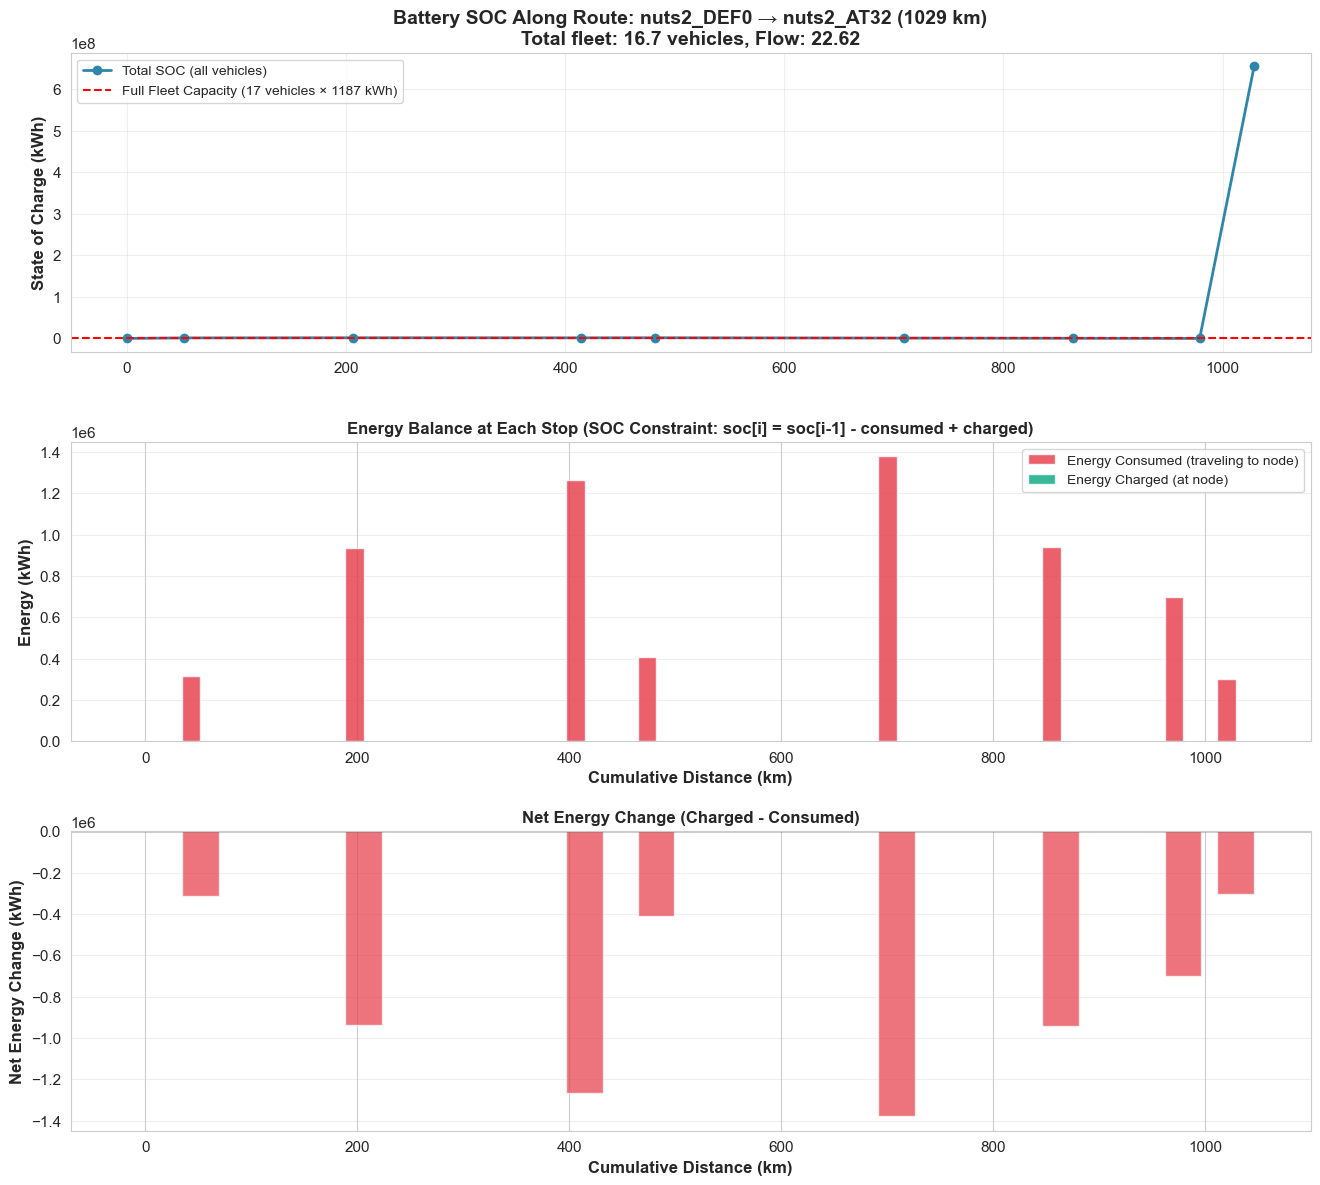


SOC STATISTICS
Route: nuts2_DEF0 → nuts2_AT32
Total distance: 1028.8 km
Number of vehicles: 16.69
Flow value: 22.62

SOC Range (total fleet):
  Minimum SOC: 18.4 kWh
  Maximum SOC: 655947591.2 kWh
  Average SOC: 73711110.6 kWh

Energy (total fleet):
  Total consumed: 6246829.9 kWh
  Total charged: 0.0 kWh
  Net energy change: 655855339.1 kWh
  Energy balance: -6246829.9 kWh

Per vehicle:
  Energy consumed per vehicle: 374395.2 kWh
  Energy charged per vehicle: 0.0 kWh

Charging Events: 0


In [ ]:
if len(soc_df) > 0:
    # Parse flow (f) and charging (s) keys similar to SOC
    # f key format: (year, (product_id, odpair_id, path_id), (mode_id, techvehicle_id), generation)
    # s key format: (year, (product_id, odpair_id, path_id, geo_id), techvehicle_id, fuel_infr_type, generation)
    
    print("Parsing flow and charging data...")
    
    def parse_f_key(key_string):
        """Parse f key: (year, (prod, od, path), (mode, tv), gen)"""
        import re
        pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
        match = re.match(pattern, key_string)
        if match:
            return {
                'year': int(match.group(1)),
                'product_id': int(match.group(2)),
                'odpair_id': int(match.group(3)),
                'path_id': int(match.group(4)),
                'mode_id': int(match.group(5)),
                'techvehicle_id': int(match.group(6)),
                'generation': int(match.group(7))
            }
        return None
    
    def parse_s_key(key_string):
        """Parse s key: (year, (prod, od, path, geo), tv, fuel_infr, gen)"""
        import re
        pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+),\s*(\d+)\),\s*(\d+),\s*(\d+),\s*(\d+)\)'
        match = re.match(pattern, key_string)
        if match:
            return {
                'year': int(match.group(1)),
                'product_id': int(match.group(2)),
                'odpair_id': int(match.group(3)),
                'path_id': int(match.group(4)),
                'geo_id': int(match.group(5)),
                'techvehicle_id': int(match.group(6)),
                'fuel_infr_type': int(match.group(7)),
                'generation': int(match.group(8))
            }
        return None
    
    # Get spec_cons for the selected vehicle
    if selected_vehicle in tv_dict:
        tv_data = tv_dict[selected_vehicle]
        # spec_cons is a list per generation
        generation_index = selected_generation - 2020  # Assuming generations start at 2020
        if isinstance(tv_data.get('spec_cons'), list):
            if generation_index < len(tv_data['spec_cons']):
                spec_cons = tv_data['spec_cons'][generation_index]
            else:
                spec_cons = tv_data['spec_cons'][0]  # Fallback to first
        else:
            spec_cons = 1.5  # Default
        print(f"Vehicle {selected_vehicle} spec_cons for generation {selected_generation}: {spec_cons} kWh/km")
    else:
        spec_cons = 1.5
        print(f"Using default spec_cons: {spec_cons} kWh/km")
    
    # Extract flow for this route
    flow_value = 0
    for key_string in f_results.keys():
        parsed_f = parse_f_key(key_string)
        if parsed_f and (
            parsed_f['year'] == selected_year and
            parsed_f['odpair_id'] == selected_odpair_id and
            parsed_f['path_id'] == selected_path_id and
            parsed_f['techvehicle_id'] == selected_vehicle and
            parsed_f['generation'] == selected_generation
        ):
            value = f_results[key_string]
            flow_value = float(value) if isinstance(value, str) else value
            break
    
    print(f"Flow (f) for this route: {flow_value:.2f}")
    
    # Calculate energy consumed and charged for each segment
    soc_df = soc_df.copy()
    soc_df['flow'] = flow_value
    
    # Energy consumed at each segment (based on actual constraint)
    # energy_consumed = distance_increment * spec_cons * num_vehicles
    # But num_vehicles in constraint is: (path.length / (W * AnnualRange)) * 1000 * flow
    # For simplification, we can use: energy = distance * spec_cons * (some factor from flow)
    # Or we can just use the SOC change and work backwards
    
    # Actually, let's calculate it properly from the constraint:
    # We need W (load capacity) and AnnualRange from vehicle data
    if selected_vehicle in tv_dict:
        tv_data = tv_dict[selected_vehicle]
        W = tv_data.get('W', [40])[generation_index] if isinstance(tv_data.get('W'), list) else tv_data.get('W', 40)
        AnnualRange = tv_data.get('AnnualRange', [100000])[generation_index] if isinstance(tv_data.get('AnnualRange'), list) else tv_data.get('AnnualRange', 100000)
    else:
        W = 40  # Default load capacity in tonnes
        AnnualRange = 100000  # Default annual range in km
    
    path_length = selected_path['length']
    num_vehicles = (path_length / (W * AnnualRange)) * 1000 * flow_value
    
    print(f"Number of vehicles (from constraint calculation): {num_vehicles:.2f}")
    print(f"  Path length: {path_length:.1f} km")
    print(f"  W (load capacity): {W} tonnes")
    print(f"  Annual range: {AnnualRange} km")
    
    # Calculate energy consumed at each node
    energy_consumed_list = []
    energy_charged_list = []
    
    for idx, row in soc_df.iterrows():
        distance_increment = row['distance_increment_km']
        geo_id = row['geo_id']
        
        # Energy consumed = distance_increment * spec_cons * num_vehicles
        energy_consumed = distance_increment * spec_cons * num_vehicles
        
        # Energy charged - look up in s_results
        energy_charged = 0
        for key_string in s_results.keys():
            parsed_s = parse_s_key(key_string)
            if parsed_s and (
                parsed_s['year'] == selected_year and
                parsed_s['odpair_id'] == selected_odpair_id and
                parsed_s['path_id'] == selected_path_id and
                parsed_s['geo_id'] == geo_id and
                parsed_s['techvehicle_id'] == selected_vehicle and
                parsed_s['generation'] == selected_generation
            ):
                value = s_results[key_string]
                s_value = float(value) if isinstance(value, str) else value
                energy_charged += s_value * 1000  # Convert to kWh (s is in MWh)
        
        energy_consumed_list.append(energy_consumed)
        energy_charged_list.append(energy_charged)
    
    soc_df['energy_consumed_kwh'] = energy_consumed_list
    soc_df['energy_charged_kwh'] = energy_charged_list
    soc_df['soc_change'] = soc_df['soc_kwh'].diff()
    
    # Verify the constraint
    print("\nVerifying SOC constraint:")
    print("SOC[i] should equal: SOC[i-1] - consumed[i] + charged[i]")
    for i in range(1, min(5, len(soc_df))):
        prev_soc = soc_df.iloc[i-1]['soc_kwh']
        curr_soc = soc_df.iloc[i]['soc_kwh']
        consumed = soc_df.iloc[i]['energy_consumed_kwh']
        charged = soc_df.iloc[i]['energy_charged_kwh']
        predicted_soc = prev_soc - consumed + charged
        error = abs(curr_soc - predicted_soc)
        print(f"  Node {i}: SOC={curr_soc:.1f}, Predicted={predicted_soc:.1f}, Error={error:.1f} kWh ({error/curr_soc*100:.2f}%)")
    
    # Create visualization with 3 subplots
    fig = plt.figure(figsize=(16, 14))
    gs = fig.add_gridspec(3, 1, hspace=0.3)
    
    # Subplot 1: SOC vs Distance
    ax1 = fig.add_subplot(gs[0])
    ax1.plot(soc_df['cumulative_distance_km'], soc_df['soc_kwh'], 
             marker='o', linewidth=2, markersize=6, color='#2E86AB', label='Total SOC (all vehicles)')
    
    # Add reference line for single vehicle capacity
    single_vehicle_capacity = tv_dict[selected_vehicle].get('battery_capacity', 1187)
    ax1.axhline(y=single_vehicle_capacity * num_vehicles, color='red', linestyle='--', linewidth=1.5, 
                label=f'Full Fleet Capacity ({num_vehicles:.0f} vehicles × {single_vehicle_capacity} kWh)')
    ax1.set_ylabel('State of Charge (kWh)', fontsize=12, fontweight='bold')
    ax1.set_title(f'Battery SOC Along Route: {selected_route["origin"]} → {selected_route["destination"]} ({selected_route["length_km"]:.0f} km)\n' +
                  f'Total fleet: {num_vehicles:.1f} vehicles, Flow: {flow_value:.2f}',
                  fontsize=14, fontweight='bold')
    ax1.legend(loc='best', fontsize=10)
    ax1.grid(True, alpha=0.3)
    
    # Mark charging locations
    charging_points = soc_df[soc_df['energy_charged_kwh'] > 10]  # Significant charging
    
    if len(charging_points) > 0:
        ax1.scatter(charging_points['cumulative_distance_km'], charging_points['soc_kwh'],
                   s=150, c='green', marker='s', zorder=5, label='Charging Stops')
        ax1.legend(loc='best', fontsize=10)
    
    # Subplot 2: Energy consumed and charged at each stop (side-by-side bars)
    ax2 = fig.add_subplot(gs[1])
    
    # Create bar positions
    x_pos = soc_df['cumulative_distance_km'].values
    width = np.min(np.diff(x_pos)) * 0.35 if len(x_pos) > 1 else 15
    
    # Energy consumed (red) and charged (green) side by side
    consumed_data = soc_df['energy_consumed_kwh'].fillna(0).values
    charged_data = soc_df['energy_charged_kwh'].fillna(0).values
    
    # Plot bars side by side
    bars_consumed = ax2.bar(x_pos - width/2, consumed_data, width=width, 
                           label='Energy Consumed (traveling to node)', 
                           color='#E63946', alpha=0.8)
    bars_charged = ax2.bar(x_pos + width/2, charged_data, width=width,
                          label='Energy Charged (at node)', 
                          color='#06A77D', alpha=0.8)
    
    ax2.set_xlabel('Cumulative Distance (km)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Energy (kWh)', fontsize=12, fontweight='bold')
    ax2.set_title('Energy Balance at Each Stop (SOC Constraint: soc[i] = soc[i-1] - consumed + charged)', 
                  fontsize=12, fontweight='bold')
    ax2.legend(loc='best', fontsize=10)
    ax2.grid(True, alpha=0.3, axis='y')
    
    # Subplot 3: Net energy change
    ax3 = fig.add_subplot(gs[2])
    net_change = charged_data - consumed_data
    colors = ['#06A77D' if x >= 0 else '#E63946' for x in net_change]
    ax3.bar(x_pos, net_change, width=width*2, color=colors, alpha=0.7)
    ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
    ax3.set_xlabel('Cumulative Distance (km)', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Net Energy Change (kWh)', fontsize=12, fontweight='bold')
    ax3.set_title('Net Energy Change (Charged - Consumed)', fontsize=12, fontweight='bold')
    ax3.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig(f'soc_visualization_{case_name}_path_{selected_path_id}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print statistics
    print("\n" + "="*80)
    print("SOC STATISTICS")
    print("="*80)
    print(f"Route: {selected_route['origin']} → {selected_route['destination']}")
    print(f"Total distance: {selected_route['length_km']:.1f} km")
    print(f"Number of vehicles: {num_vehicles:.2f}")
    print(f"Flow value: {flow_value:.2f}")
    
    print(f"\nSOC Range (total fleet):")
    print(f"  Minimum SOC: {soc_df['soc_kwh'].min():.1f} kWh")
    print(f"  Maximum SOC: {soc_df['soc_kwh'].max():.1f} kWh")
    print(f"  Average SOC: {soc_df['soc_kwh'].mean():.1f} kWh")
    
    print(f"\nEnergy (total fleet):")
    print(f"  Total consumed: {soc_df['energy_consumed_kwh'].sum():.1f} kWh")
    print(f"  Total charged: {soc_df['energy_charged_kwh'].sum():.1f} kWh")
    print(f"  Net energy change: {soc_df['soc_change'].sum():.1f} kWh")
    print(f"  Energy balance: {(soc_df['energy_charged_kwh'].sum() - soc_df['energy_consumed_kwh'].sum()):.1f} kWh")
    
    print(f"\nPer vehicle:")
    if num_vehicles > 0:
        print(f"  Energy consumed per vehicle: {soc_df['energy_consumed_kwh'].sum() / num_vehicles:.1f} kWh")
        print(f"  Energy charged per vehicle: {soc_df['energy_charged_kwh'].sum() / num_vehicles:.1f} kWh")
    
    print(f"\nCharging Events: {len(charging_points)}")
    if len(charging_points) > 0:
        print(f"Charging locations:")
        for idx, row in charging_points.iterrows():
            print(f"  - {row['geo_name']} at {row['cumulative_distance_km']:.1f} km")
            print(f"    Charged: {row['energy_charged_kwh']:.1f} kWh, Consumed to get here: {row['energy_consumed_kwh']:.1f} kWh")
else:
    print("Cannot create visualization - no SOC data found for this route.")
    print("This might mean:")
    print("  1. The route is not used in the solution (no flow)")
    print("  2. The route uses non-BEV vehicles")
    print("  3. The SOC tracking is not active for this route")

## 5. Visualize SOC Development Along Route

Average consumption rate: 2544.225 kWh/km


C:\Users\simuser\AppData\Local\Temp\ipykernel_22028\2939631558.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


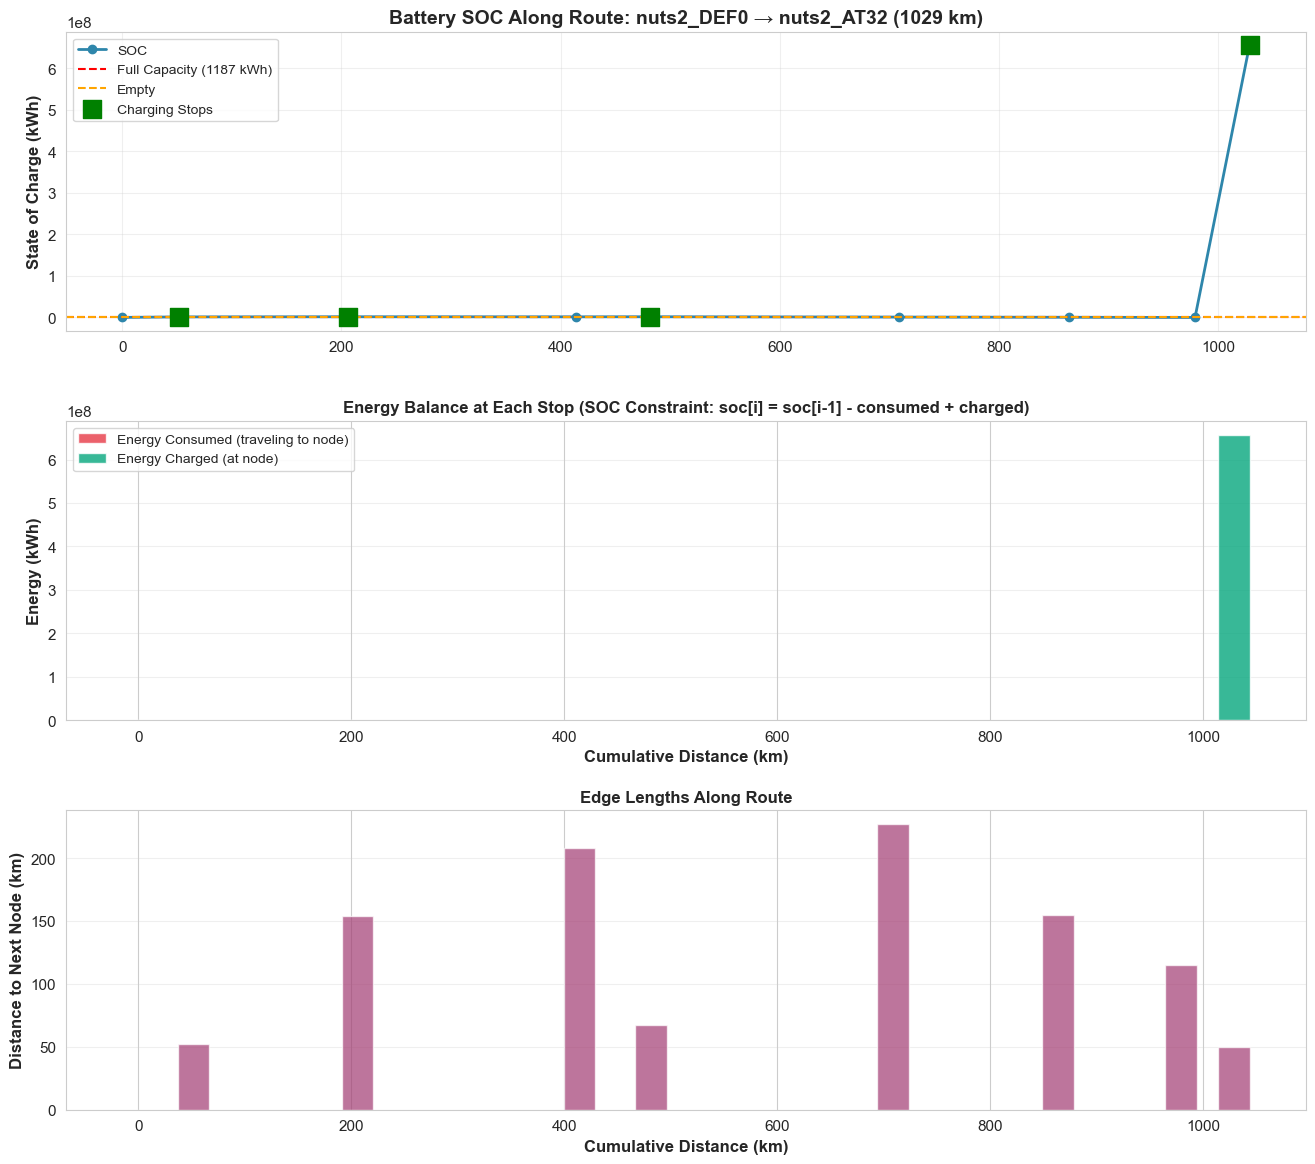


SOC STATISTICS
Route: nuts2_DEF0 → nuts2_AT32
Total distance: 1028.8 km
Baseline travel time: 0.00 hours

SOC Range:
  Minimum SOC: 18.4 kWh (1.5%)
  Maximum SOC: 655947591.2 kWh (55260959.7%)
  Average SOC: 73711110.6 kWh (6209866.1%)

Energy Consumption:
  Total consumed: 2617565.5 kWh
  Total charged: 658852650.1 kWh
  Net energy change: 655855339.1 kWh

Charging Events: 4
Charging locations:
  - nuts2_DE60 at 51.9 km
    SOC: 1290897.7 kWh, Charged: 1330737.4 kWh
  - nuts2_DE93 at 206.1 km
    SOC: 1635474.5 kWh, Charged: 736871.1 kWh
  - nuts2_DE73 at 481.9 km
    SOC: 1644755.8 kWh, Charged: 331195.4 kWh
  - nuts2_AT32 at 1028.8 km
    SOC: 655947591.2 kWh, Charged: 656074100.8 kWh


In [ ]:
if len(soc_df) > 0:
    # Calculate energy consumed and energy charged at each node
    # Based on SOC constraint: soc[current] = soc[previous] - energy_consumed + energy_charged
    # Therefore: soc_change = soc[current] - soc[previous] = -energy_consumed + energy_charged
    
    soc_df = soc_df.copy()
    soc_df['soc_change'] = soc_df['soc_kwh'].diff()
    
    # Estimate energy consumed based on distance and average consumption rate
    # First, find segments where SOC decreased (no charging)
    consumption_segments = soc_df[(soc_df['soc_change'] < 0) & (soc_df['distance_increment_km'] > 0)].copy()
    
    if len(consumption_segments) > 0:
        avg_consumption_per_km = -consumption_segments['soc_change'].sum() / consumption_segments['distance_increment_km'].sum()
    else:
        avg_consumption_per_km = 1.5  # Default assumption: 1.5 kWh/km for BEV trucks
    
    print(f"Average consumption rate: {avg_consumption_per_km:.3f} kWh/km")
    
    # Calculate energy consumed and charged for each segment
    soc_df['energy_consumed_kwh'] = soc_df['distance_increment_km'] * avg_consumption_per_km
    # Energy charged = energy consumed + soc_change (because soc_change = -consumed + charged)
    soc_df['energy_charged_kwh'] = soc_df['energy_consumed_kwh'] + soc_df['soc_change']
    # Set negative charging to zero (means no charging occurred)
    soc_df['energy_charged_kwh'] = soc_df['energy_charged_kwh'].clip(lower=0)
    
    # Create visualization with 3 subplots
    fig = plt.figure(figsize=(16, 14))
    gs = fig.add_gridspec(3, 1, hspace=0.3)
    
    # Subplot 1: SOC vs Distance
    ax1 = fig.add_subplot(gs[0])
    ax1.plot(soc_df['cumulative_distance_km'], soc_df['soc_kwh'], 
             marker='o', linewidth=2, markersize=6, color='#2E86AB', label='SOC')
    ax1.axhline(y=1187, color='red', linestyle='--', linewidth=1.5, label='Full Capacity (1187 kWh)')
    ax1.axhline(y=0, color='orange', linestyle='--', linewidth=1.5, label='Empty')
    ax1.set_ylabel('State of Charge (kWh)', fontsize=12, fontweight='bold')
    ax1.set_title(f'Battery SOC Along Route: {selected_route["origin"]} → {selected_route["destination"]} ({selected_route["length_km"]:.0f} km)',
                  fontsize=14, fontweight='bold')
    ax1.legend(loc='best', fontsize=10)
    ax1.grid(True, alpha=0.3)
    
    # Mark charging locations (where SOC increases)
    charging_points = soc_df[soc_df['soc_change'] > 50]  # Significant increase = charging
    
    if len(charging_points) > 0:
        ax1.scatter(charging_points['cumulative_distance_km'], charging_points['soc_kwh'],
                   s=150, c='green', marker='s', zorder=5, label='Charging Stops')
        ax1.legend(loc='best', fontsize=10)
    
    # Subplot 2: Energy consumed and charged at each stop (stacked bars)
    ax2 = fig.add_subplot(gs[1])
    
    # Create bar positions
    x_pos = soc_df['cumulative_distance_km'].values
    width = np.min(np.diff(x_pos)) * 0.6 if len(x_pos) > 1 else 20
    
    # Energy consumed (red, downward)
    consumed_data = soc_df['energy_consumed_kwh'].fillna(0).values
    # Energy charged (green, upward)
    charged_data = soc_df['energy_charged_kwh'].fillna(0).values
    
    # Plot bars
    bars_consumed = ax2.bar(x_pos, consumed_data, width=width, 
                           label='Energy Consumed (traveling to node)', 
                           color='#E63946', alpha=0.8)
    bars_charged = ax2.bar(x_pos, charged_data, width=width, 
                          bottom=consumed_data,
                          label='Energy Charged (at node)', 
                          color='#06A77D', alpha=0.8)
    
    ax2.set_xlabel('Cumulative Distance (km)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Energy (kWh)', fontsize=12, fontweight='bold')
    ax2.set_title('Energy Balance at Each Stop (SOC Constraint: soc[i] = soc[i-1] - consumed + charged)', 
                  fontsize=12, fontweight='bold')
    ax2.legend(loc='best', fontsize=10)
    ax2.grid(True, alpha=0.3, axis='y')
    
    # Subplot 3: Distance increments
    ax3 = fig.add_subplot(gs[2])
    ax3.bar(soc_df['cumulative_distance_km'], soc_df['distance_increment_km'],
            width=width, color='#A23B72', alpha=0.7)
    ax3.set_xlabel('Cumulative Distance (km)', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Distance to Next Node (km)', fontsize=12, fontweight='bold')
    ax3.set_title('Edge Lengths Along Route', fontsize=12, fontweight='bold')
    ax3.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig(f'soc_visualization_{case_name}_path_{selected_path_id}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print statistics
    print("\n" + "="*80)
    print("SOC STATISTICS")
    print("="*80)
    print(f"Route: {selected_route['origin']} → {selected_route['destination']}")
    print(f"Total distance: {selected_route['length_km']:.1f} km")
    print(f"Baseline travel time: {selected_route['baseline_time']:.2f} hours")
    print(f"\nSOC Range:")
    print(f"  Minimum SOC: {soc_df['soc_kwh'].min():.1f} kWh ({soc_df['soc_kwh'].min()/1187*100:.1f}%)")
    print(f"  Maximum SOC: {soc_df['soc_kwh'].max():.1f} kWh ({soc_df['soc_kwh'].max()/1187*100:.1f}%)")
    print(f"  Average SOC: {soc_df['soc_kwh'].mean():.1f} kWh ({soc_df['soc_kwh'].mean()/1187*100:.1f}%)")
    
    print(f"\nEnergy Consumption:")
    print(f"  Total consumed: {soc_df['energy_consumed_kwh'].sum():.1f} kWh")
    print(f"  Total charged: {soc_df['energy_charged_kwh'].sum():.1f} kWh")
    print(f"  Net energy change: {soc_df['soc_change'].sum():.1f} kWh")
    
    print(f"\nCharging Events: {len(charging_points)}")
    if len(charging_points) > 0:
        print(f"Charging locations:")
        for idx, row in charging_points.iterrows():
            print(f"  - {row['geo_name']} at {row['cumulative_distance_km']:.1f} km")
            print(f"    SOC: {row['soc_kwh']:.1f} kWh, Charged: {row['energy_charged_kwh']:.1f} kWh")
else:
    print("Cannot create visualization - no SOC data found for this route.")
    print("This might mean:")
    print("  1. The route is not used in the solution (no flow)")
    print("  2. The route uses non-BEV vehicles")
    print("  3. The SOC tracking is not active for this route")

## 6. Try Alternative Routes if Needed

In [ ]:
# If the first route had no data, try to find routes that DO have SOC data
if len(soc_df) == 0:
    print("Searching for routes with SOC data...\n")
    
    # Use the parsed_keys from cell 14
    if 'parsed_keys' in locals() and len(parsed_keys) > 0:
        # Extract all unique path IDs with non-zero SOC
        paths_with_soc = set()
        for key_string, parsed in parsed_keys.items():
            value = soc_results[key_string]
            soc_value = float(value) if isinstance(value, str) else value
            if soc_value > 0:
                paths_with_soc.add(parsed['path_id'])
        
        print(f"Found {len(paths_with_soc)} paths with SOC data in results")
        
        # Find routes with SOC data from our candidate lists
        found_alternatives = False
        
        if 'de_at_df' in locals() and len(de_at_df) > 0:
            routes_with_soc = de_at_df[de_at_df['path_id'].isin(paths_with_soc)]
            if len(routes_with_soc) > 0:
                print(f"\nFound {len(routes_with_soc)} DE→AT routes with SOC data:")
                print(routes_with_soc.head(10))
                print("\n" + "="*80)
                print("To visualize one of these routes, copy and paste:")
                print(f"selected_path_id = {routes_with_soc.iloc[0]['path_id']}")
                print(f"selected_odpair_id = {routes_with_soc.iloc[0]['odpair_id']}")
                print("Then re-run cells 12-16")
                found_alternatives = True
        
        if 'long_paths_df' in locals() and len(long_paths_df) > 0:
            routes_with_soc = long_paths_df[long_paths_df['path_id'].isin(paths_with_soc)]
            if len(routes_with_soc) > 0:
                print(f"\nFound {len(routes_with_soc)} long routes with SOC data:")
                print(routes_with_soc.head(10))
                print("\n" + "="*80)
                print("To visualize one of these routes, copy and paste:")
                print(f"selected_path_id = {routes_with_soc.iloc[0]['path_id']}")
                print(f"selected_odpair_id = {routes_with_soc.iloc[0]['odpair_id']}")
                print("Then re-run cells 12-16")
                found_alternatives = True
        
        if not found_alternatives and len(paths_with_soc) > 0:
            print("\n" + "="*80)
            print("Showing sample paths with SOC data:")
            
            paths_with_data = []
            for path_id in sorted(list(paths_with_soc))[:20]:  # Check first 20
                if path_id in path_dict:
                    path = path_dict[path_id]
                    # Find corresponding OD pair
                    odpair = next((od for od in odpairs if od['path_id'] == path_id), None)
                    if odpair:
                        origin = geo_dict[odpair['from']]['name']
                        dest = geo_dict[odpair['to']]['name']
                        origin_country = geo_dict[odpair['from']].get('country', 'XX')
                        dest_country = geo_dict[odpair['to']].get('country', 'XX')
                        paths_with_data.append({
                            'path_id': path_id,
                            'odpair_id': odpair['id'],
                            'origin': origin,
                            'destination': dest,
                            'countries': f"{origin_country}→{dest_country}",
                            'length_km': path['length']
                        })
            
            if len(paths_with_data) > 0:
                paths_df = pd.DataFrame(paths_with_data).sort_values('length_km', ascending=False)
                print(paths_df.head(15))
                print("\n" + "="*80)
                print("To visualize one of these routes, copy and paste:")
                print(f"selected_path_id = {paths_df.iloc[0]['path_id']}")
                print(f"selected_odpair_id = {paths_df.iloc[0]['odpair_id']}")
                print("Then re-run cells 12-16")
    else:
        print("ERROR: parsed_keys not found. Please re-run cell 14 first.")
else:
    print("✓ Route has SOC data - visualization created successfully!")

✓ Route has SOC data - visualization created successfully!


## 7. Additional Analysis: Energy Consumption Rate

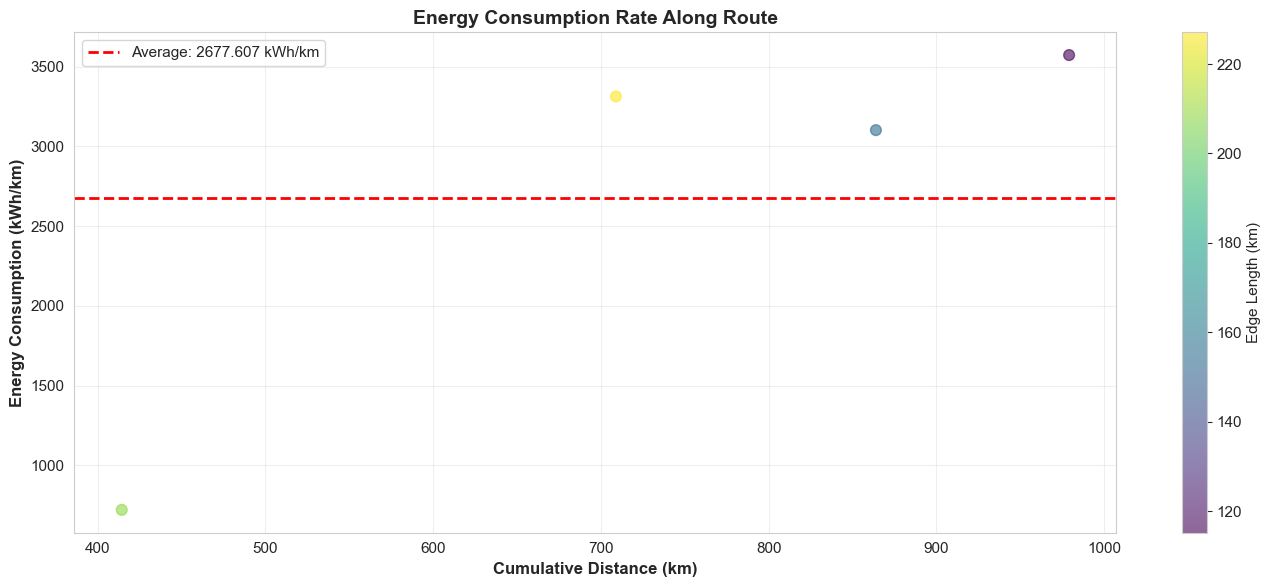


Energy Consumption Statistics:
  Average: 2677.607 kWh/km
  Min: 721.113 kWh/km
  Max: 3573.138 kWh/km
  Std: 1318.463 kWh/km


In [ ]:
if len(soc_df) > 1:
    # Calculate energy consumption between nodes
    soc_df['soc_change'] = -soc_df['soc_kwh'].diff()  # Negative diff = consumption
    soc_df['consumption_per_km'] = soc_df['soc_change'] / soc_df['distance_increment_km']
    
    # Filter out charging events (positive changes) and first row
    consumption_data = soc_df[(soc_df['soc_change'] > 0) & (soc_df['distance_increment_km'] > 0)].copy()
    
    if len(consumption_data) > 0:
        plt.figure(figsize=(14, 6))
        plt.scatter(consumption_data['cumulative_distance_km'], 
                   consumption_data['consumption_per_km'],
                   s=60, alpha=0.6, c=consumption_data['distance_increment_km'], 
                   cmap='viridis')
        plt.colorbar(label='Edge Length (km)')
        plt.axhline(y=consumption_data['consumption_per_km'].mean(), 
                   color='red', linestyle='--', linewidth=2,
                   label=f'Average: {consumption_data["consumption_per_km"].mean():.3f} kWh/km')
        plt.xlabel('Cumulative Distance (km)', fontsize=12, fontweight='bold')
        plt.ylabel('Energy Consumption (kWh/km)', fontsize=12, fontweight='bold')
        plt.title('Energy Consumption Rate Along Route', fontsize=14, fontweight='bold')
        plt.legend(fontsize=11)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(f'energy_consumption_{case_name}_path_{selected_path_id}.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print("\nEnergy Consumption Statistics:")
        print(f"  Average: {consumption_data['consumption_per_km'].mean():.3f} kWh/km")
        print(f"  Min: {consumption_data['consumption_per_km'].min():.3f} kWh/km")
        print(f"  Max: {consumption_data['consumption_per_km'].max():.3f} kWh/km")
        print(f"  Std: {consumption_data['consumption_per_km'].std():.3f} kWh/km")